## install packages

In [1]:
%pip install -q pandas==<ver> matplotlib==<ver> pyarrow==<ver> duckdb==<ver>

/bin/bash: -c: line 1: syntax error near unexpected token `newline'
/bin/bash: -c: line 1: `/usr/local/bin/python -m pip install -q pandas==<ver> matplotlib==<ver> pyarrow==<ver> duckdb==<ver>'
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip list | grep -iE "^(pandas|matplotlib|pyarrow|duckdb) "

duckdb                    1.5.6
matplotlib                3.11.2
pandas                    3.0.6
pyarrow                   26.0.0
Note: you may need to restart the kernel to use updated packages.


## Settings

In [4]:
import os
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass



# Main folder

WORK = Path("/workspace")


if not WORK.exists():
    raise FileNotFoundError("/workspace not found - check that the RunPod volume is attached.")


# Folders we use

SETUP      = WORK / "AMI-diarization-setup"
AUDIO_ROOT = SETUP / "pyannote" / "amicorpus"   
ANNOT_DIR  = WORK / "ami_annotations"           
RESULTS    = WORK / "results" / "data"         
FIGURES    = WORK / "results" / "figures"       
LOG_DIR    = WORK / "logs"                     
ENV        = WORK / "envs" / "pyannote21"      


PROCESSED   = WORK / "data_processed"       
AUDIO_FIXED = PROCESSED / "audio_fixed"     
RTTM_CLEAN  = PROCESSED / "rttm_clean" 
# Data choices

SPLITS        = ["train", "dev", "test"]   
EVAL_SPLIT    = "test"                    
REFERENCE_SET = "only_words"              


# Scoring choices

AUDIO_TYPE   = "Mix-Headset"  
COLLAR       = 0.0            
SKIP_OVERLAP = False           

PIPELINE_REPO     = "pyannote/speaker-diarization"
PIPELINE_REVISION = "2.1"

# Run ID and seed

# Run ID = today's date and time, so files from different runs have different names
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

# Seed = fixed number so random steps give the same result every time
SEED = 42


# Hugging Face token 

# First, look for a saved token
HF_TOKEN = os.environ.get("HF_TOKEN")

# If there is no saved token, ask for it (what you type stays hidden)
if not HF_TOKEN:
    HF_TOKEN = getpass("Paste your Hugging Face token: ")

# If still no token, stop with a clear message
if not HF_TOKEN:
    raise ValueError("No Hugging Face token given - the pyannote model download will fail.")

# Save the token so the other cells can use it
os.environ["HF_TOKEN"] = HF_TOKEN



# Websites we download from

AMI_MIRROR      = "https://groups.inf.ed.ac.uk/ami/AMICorpusMirror/amicorpus"
ANNOTATIONS_URL = "https://groups.inf.ed.ac.uk/ami/AMICorpusAnnotations/ami_public_manual_1.6.2.zip"
SETUP_REPO      = "https://github.com/pyannote/AMI-diarization-setup.git"



# Make the output folders

for folder in [RESULTS, FIGURES, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)



# Print a short summary

print("Working folder :", WORK)
print("Run ID         :", RUN_ID, "(UTC)")
print("Eval split     :", EVAL_SPLIT)
print("Reference set  :", REFERENCE_SET)
print("Audio type     :", AUDIO_TYPE)
print("Collar         :", COLLAR)
print("Skip overlap   :", SKIP_OVERLAP)
print("Baseline model :", PIPELINE_REPO, "@", PIPELINE_REVISION)
print("Seed           :", SEED)
print("Hugging Face token loaded")

Working folder : /workspace
Run ID         : 20261021_081634 (UTC)
Eval split     : test
Reference set  : only_words
Audio type     : Mix-Headset
Collar         : 0.0
Skip overlap   : False
Baseline model : pyannote/speaker-diarization @ 2.1
Seed           : 42
Hugging Face token loaded


## Check Hugging Face access
Checks the token and access to pyannote 2.1 models.

In [5]:
# CHECK HUGGING FACE TOKEN AND MODEL ACCESS


import json
import urllib.request
import urllib.error


def hf_request(url):

    req = urllib.request.Request(url, headers={"Authorization": f"Bearer {HF_TOKEN}"})
    try:
        with urllib.request.urlopen(req, timeout=20) as resp:
            return resp.status, resp.read()
    except urllib.error.HTTPError as e:   
        return e.code, b""
    except urllib.error.URLError:        
        return 0, b""



# Is the token valid?

status, body = hf_request("https://huggingface.co/api/whoami-v2")

if status == 200:
    print("Token valid. Logged in as:", json.loads(body)["name"])
elif status == 0:
    raise ConnectionError("Could not reach huggingface.co - check the pod's internet connection.")
else:
    raise ValueError(f"Token rejected (HTTP {status}) - create a new one at huggingface.co/settings/tokens")



# Can we download the models we need?

models_to_check = [
    (PIPELINE_REPO, PIPELINE_REVISION),     
    ("pyannote/segmentation", "2022.07"),   
]

problems = []  

for repo, version in models_to_check:
    status, _ = hf_request(f"https://huggingface.co/{repo}/resolve/{version}/config.yaml")

    if status == 200:
        print(f"{repo} @ {version}: access granted")
    elif status in (401, 403):
        problems.append(f"{repo}: no access -> open huggingface.co/{repo} and accept the conditions")
    elif status == 404:
        problems.append(f"{repo}: version '{version}' not found -> check the tag name under 'Files and versions'")
    else:
        problems.append(f"{repo}: unexpected HTTP {status} -> open huggingface.co/{repo} and check the page")

if problems:
    raise PermissionError("Fix these before running the baseline:\n  " + "\n  ".join(problems))



# Save the pipeline's settings file 

status, body = hf_request(f"https://huggingface.co/{PIPELINE_REPO}/resolve/{PIPELINE_REVISION}/config.yaml")
config_file = LOG_DIR / f"pipeline_config_{RUN_ID}.yaml"
config_file.write_bytes(body)

print("\nPipeline config saved to:", config_file)
print("-" * 50)
print(body.decode("utf-8"))
print("All checks passed")

Token valid. Logged in as: pipelix
pyannote/speaker-diarization @ 2.1: access granted
pyannote/segmentation @ 2022.07: access granted

Pipeline config saved to: /workspace/logs/pipeline_config_20261021_081634.yaml
--------------------------------------------------
pipeline:
  name: pyannote.audio.pipelines.SpeakerDiarization
  params:
    clustering: AgglomerativeClustering
    embedding: speechbrain/spkrec-ecapa-voxceleb
    embedding_batch_size: 32
    embedding_exclude_overlap: true
    segmentation: pyannote/segmentation@2022.07
    segmentation_batch_size: 32

params:
  clustering:
    method: centroid
    min_cluster_size: 15
    threshold: 0.7153814381597874
  segmentation:
    min_duration_off: 0.5817029604921046
    threshold: 0.4442333667381752

All checks passed


## AMI splits and leakage checks
Loads official train/dev/test splits and checks for leakage.

In [6]:
import json
import subprocess



# AMI diarization setup 

if (SETUP / "lists").exists():
    print("Setup repo already downloaded - skipping.")
else:
    print("Downloading the AMI diarization setup repo...")
    subprocess.run(["git", "clone", "--quiet", SETUP_REPO, str(SETUP)], check=True)


commit = subprocess.run(["git", "-C", str(SETUP), "rev-parse", "HEAD"],
                        capture_output=True, text=True, check=True).stdout.strip()
print("Setup repo commit:", commit)



# Read the official meeting lists

meetings = {}   

for split in SPLITS:
    list_file = SETUP / "lists" / f"{split}.meetings.txt"
    meetings[split] = list_file.read_text().split()
    print(f"{split:5s}: {len(meetings[split]):3d} meetings   e.g. {meetings[split][:3]}")

all_ids = [m for split in SPLITS for m in meetings[split]]
print("Total:", len(all_ids), "meetings")
print()



# Check 1 - each split has the expected number of meetings

expected = {"train": 136, "dev": 18, "test": 16}

for split in SPLITS:
    found = len(meetings[split])
    assert found == expected[split], f"{split}: expected {expected[split]} meetings, found {found}"
print("Check 1 passed: split sizes are correct (136 / 18 / 16)")



# Check 2 - leakage: no meeting is in more than one split

assert len(all_ids) == len(set(all_ids)), "A meeting appears in two splits!"
print("Check 2 passed: no meeting appears in two splits")



# Check 3 - leakage: meeting series

def series_name(meeting_id):
   
    return meeting_id[:-1] if meeting_id[-1].isalpha() else meeting_id

series_splits = {}   
for split in SPLITS:
    for m in meetings[split]:
        series_splits.setdefault(series_name(m), set()).add(split)

shared = {s: sorted(splits) for s, splits in series_splits.items() if len(splits) > 1}
if shared:
    print(f"Check 3 NOTE: {len(shared)} meeting series appear in more than one split:")
    for s, splits in shared.items():
        print(f"   {s}: {splits}")
else:
    print(f"Check 3 passed: all {len(series_splits)} meeting series stay inside one split")



# Check 4 - every meeting has a reference file (RTTM) and a scoring-region file (UEM)

rttm_names = {p.stem for p in (SETUP / REFERENCE_SET).rglob("*.rttm")}
uem_names  = {p.stem for p in SETUP.rglob("*.uem")}

missing = []
for m in all_ids:
    if m not in rttm_names:
        missing.append(f"{m}: no RTTM")
    if m not in uem_names:
        missing.append(f"{m}: no UEM")

assert not missing, "Missing files:\n  " + "\n  ".join(missing)
print(f"Check 4 passed: all {len(all_ids)} meetings have an RTTM ({REFERENCE_SET}) and a UEM file")



# Save the split lists together 

splits_file = LOG_DIR / f"splits_{RUN_ID}.json"
splits_record = {
    "setup_commit": commit,
    "reference_set": REFERENCE_SET,
    "meetings": meetings,
}
splits_file.write_text(json.dumps(splits_record, indent=2))
print()
print("Splits saved to:", splits_file)

Setup repo already downloaded - skipping.
Setup repo commit: 67c2d539286e89f68952d5dcf83912bd9f01dfae
train: 136 meetings   e.g. ['IS1000a', 'IS1000b', 'IS1000c']
dev  :  18 meetings   e.g. ['IS1008a', 'IS1008b', 'IS1008c']
test :  16 meetings   e.g. ['IS1009a', 'IS1009b', 'IS1009c']
Total: 170 meetings

Check 1 passed: split sizes are correct (136 / 18 / 16)
Check 2 passed: no meeting appears in two splits
Check 3 passed: all 58 meeting series stay inside one split
Check 4 passed: all 170 meetings have an RTTM (only_words) and a UEM file

Splits saved to: /workspace/logs/splits_20261021_081634.json


## Safe Download Functions

We use two helper functions to download files safely:

- **`remote_size(url)`:** Checks the file size before downloading.
- **`download(url, destination)`:** Skips completed files, downloads new files using a temporary `.part` file, verifies their size, and retries up to 3 times if needed.

All download results (**OK, SKIP, FAIL**) are recorded in a log file.

In [7]:
import urllib.request
import logging
import shutil
import time



# Logging: everything goes to a file, failures also show here

log_file = LOG_DIR / f"download_{RUN_ID}.log"

file_handler = logging.FileHandler(log_file)     
screen_handler = logging.StreamHandler()          
screen_handler.setLevel(logging.WARNING)

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s %(levelname)s %(message)s",
                    handlers=[file_handler, screen_handler],
                    force=True)



# Ask the server how big a file 

def remote_size(url):

    try:
        request = urllib.request.Request(url, method="HEAD")
        with urllib.request.urlopen(request, timeout=60) as response:
            size = response.headers.get("Content-Length")
            return int(size) if size else None
    except Exception as error:
        logging.warning(f"Could not get size for {url}: {error}")
        return None



# Download one file safely

def download(url, destination, retries=3):
   
    destination.parent.mkdir(parents=True, exist_ok=True)   # make the folder if needed
    expected = remote_size(url)

    
    if destination.exists():
        if expected is None or destination.stat().st_size == expected:
            logging.info(f"SKIP {destination.name} (already complete)")
            return "skipped"
        logging.info(f"REDO {destination.name} (size {destination.stat().st_size}, expected {expected})")


    temporary = destination.with_name(destination.name + ".part")

    for attempt in range(1, retries + 1):
        try:
            with urllib.request.urlopen(url, timeout=60) as response, open(temporary, "wb") as out:
                shutil.copyfileobj(response, out)

           
            got = temporary.stat().st_size
            if expected is not None and got != expected:
                raise IOError(f"size mismatch: got {got}, expected {expected}")

            # Complete -> give it its real name
            temporary.replace(destination)
            logging.info(f"OK   {destination.name} ({got / 1e6:.1f} MB)")
            return "downloaded"

        except Exception as error:
            temporary.unlink(missing_ok=True)               
            logging.warning(f"FAIL {destination.name} attempt {attempt}/{retries}: {error}")
            if attempt == retries:
                raise                                       
            time.sleep(5 * attempt)                         


print("Helpers ready. Log file:", log_file)

Helpers ready. Log file: /workspace/logs/download_20261021_081634.log


## Download audio
Downloads AMI **Mix-Headset** audio (16 kHz, mono WAV) for all 170 meetings, ~100 hours.
Test meetings first, 2 files at a time. Complete files are skipped, so it is safe to re-run.
Stops with an error if any file is missing, and saves an audio list to `results/data/`.

In [8]:
import shutil
import logging
import pandas as pd
from concurrent.futures import ThreadPoolExecutor



# Where each meeting's audio lives 

def audio_url(meeting):

    return f"{AMI_MIRROR}/{meeting}/audio/{meeting}.{AUDIO_TYPE}.wav"

def audio_path(meeting):

    return AUDIO_ROOT / meeting / "audio" / f"{meeting}.{AUDIO_TYPE}.wav"



# Which meetings do we need?

all_meetings = meetings["test"] + meetings["dev"] + meetings["train"]
not_on_disk  = [m for m in all_meetings if not audio_path(m).exists()]
print(f"Meetings: {len(all_meetings)} total, {len(not_on_disk)} not on disk yet")



# Check disk space 

free_gb = shutil.disk_usage(WORK).free / 1e9
print(f"Free space: {free_gb:.1f} GB")
if not_on_disk and free_gb < 15:
    raise RuntimeError(f"Only {free_gb:.1f} GB free - need about 15 GB for the audio.")



# Download (2 files at a time, to be polite to the AMI server)

def get_meeting(meeting):
  
    try:
        return download(audio_url(meeting), audio_path(meeting))
    except Exception as error:
        logging.error(f"GAVE UP {meeting}: {error}")  
        return "FAILED"

results = {}
with ThreadPoolExecutor(max_workers=2) as pool:
    outcomes = pool.map(get_meeting, all_meetings)   
    for meeting, result in zip(all_meetings, outcomes):
        results[meeting] = result
        if result != "skipped":                       
            print(f"{meeting}: {result}")

statuses = list(results.values())
print()
print("Downloaded :", statuses.count("downloaded"))
print("Skipped    :", statuses.count("skipped"), "(already complete)")
print("Failed     :", statuses.count("FAILED"))



# Final check: is every file really on disk?

missing = [m for m in all_meetings if not audio_path(m).exists()]
if missing:
    raise RuntimeError(f"{len(missing)} meetings missing: {missing}\n"
                       f"Run this cell again - complete files are skipped.")
print(f"All {len(all_meetings)} meetings are on disk.")



# Save a list of the audio files 

split_of = {m: split for split in SPLITS for m in meetings[split]}  

manifest = pd.DataFrame({
    "meeting": all_meetings,
    "split":   [split_of[m] for m in all_meetings],
    "size_mb": [round(audio_path(m).stat().st_size / 1e6, 1) for m in all_meetings],
})
manifest_file = RESULTS / f"audio_manifest_{RUN_ID}.csv"
manifest.to_csv(manifest_file, index=False)

print(f"Total audio: {manifest['size_mb'].sum() / 1000:.1f} GB")
print("Audio list saved to:", manifest_file)

Meetings: 170 total, 0 not on disk yet
Free space: 41.1 GB

Downloaded : 0
Skipped    : 170 (already complete)
Failed     : 0
All 170 meetings are on disk.
Total audio: 11.5 GB
Audio list saved to: /workspace/results/data/audio_manifest_20261021_081634.csv


## Download AMI Manual Annotations

We download the AMI manual annotations (version 1.6.2), which include word transcripts, timestamps, summaries, and decisions.

- **Evaluation:** RTTM files from **Dataset Splits** are used for diarization scoring. Word transcripts are used later for WER and action-item extraction.
- **Verification:** Record the ZIP file's SHA-256 hash for reproducibility.
- **Validation:** Check the ZIP for corruption and extract it only once.

In [9]:
# AMI MANUAL ANNOTATIONS v1.6.2


import zipfile
import hashlib
import logging


zip_path = ANNOT_DIR / "ami_public_manual_1.6.2.zip"
status = download(ANNOTATIONS_URL, zip_path)
print("Annotations zip:", status)

# Fingerprint (SHA-256): proves exactly which file we used

sha256 = hashlib.sha256(zip_path.read_bytes()).hexdigest()
print("SHA-256:", sha256)
logging.info(f"annotations zip sha256 {sha256}")



# Unzip - only if not done yet, or if the zip has changed

marker = ANNOT_DIR / ".unzipped"     

if marker.exists() and marker.read_text() == sha256:
    print("Already unzipped - skipping.")
else:
    with zipfile.ZipFile(zip_path) as archive:
        broken = archive.testzip()   
        if broken is not None:
            raise IOError(f"Corrupted file in zip: {broken} - delete the zip and re-run")
        archive.extractall(ANNOT_DIR)
    marker.write_text(sha256)
    print("Unzipped.")

folders = sorted(p.name for p in ANNOT_DIR.iterdir() if p.is_dir())
print("Folders:", folders)



# Check: every meeting in our splits has word transcripts

words_dir = next(ANNOT_DIR.rglob("words"), None)
assert words_dir is not None, "No 'words' folder found in the annotations!"

word_files = list(words_dir.glob("*.words.xml"))
meetings_with_words = {f.name.split(".")[0] for f in word_files}  
print(f"Word files: {len(word_files)} covering {len(meetings_with_words)} meetings")

no_words = [m for m in all_ids if m not in meetings_with_words]
assert not no_words, f"No word transcripts for: {no_words}"
print(f"All {len(all_ids)} split meetings have word transcripts")

print("In annotations but not in splits:", meetings_with_words - set(all_ids))

Annotations zip: skipped
SHA-256: b56e5babb2496b8795deeeda7e71178d7fbc9963f94276cf2a3f4b56ebbc9f9d
Already unzipped - skipping.
Folders: ['abstractive', 'argumentation', 'configuration', 'corpusResources', 'corpusdoc', 'decision', 'dialogueActs', 'disfluency', 'extractive', 'focus', 'handGesture', 'headGesture', 'movement', 'namedEntities', 'ontologies', 'participantRoles', 'participantSummaries', 'segments', 'topics', 'words', 'youUsages']
Word files: 687 covering 171 meetings
All 170 split meetings have word transcripts
In annotations but not in splits: {'IB4005'}


In [10]:
# SPEAKER-LEVEL LEAKAGE CHECK


import json
import xml.etree.ElementTree as ET


def local_tag(element):
    
    return element.tag.split("}")[-1]

# Read which people took part in each meeting

meetings_xml = next(ANNOT_DIR.rglob("meetings.xml"), None)
assert meetings_xml is not None, "meetings.xml not found in the annotations"

people_in = {}   # e.g. {"ES2002a": {"FEE005", "MEE006", ...}}
for element in ET.parse(meetings_xml).iter():
    if local_tag(element) == "meeting":
        meeting_id = element.get("observation")
        speakers = {s.get("global_name") for s in element.iter() if local_tag(s) == "speaker"}
        people_in[meeting_id] = speakers - {None}

# Safety check: did we actually find speaker IDs?
if not any(people_in.values()):
    raise ValueError("Could not read speaker IDs from meetings.xml - send me its first 20 lines.")


# Which people are in each split?

people_per_split = {}
for split in SPLITS:
    people = set()
    for m in meetings[split]:
        people |= people_in.get(m, set())
    people_per_split[split] = people
    print(f"{split:5s}: {len(people):3d} different speakers")

no_info = [m for m in all_ids if m not in people_in]
if no_info:
    print("No speaker info for:", no_info)


# Who appears in more than one split? (we REPORT, not stop)

overlap = {
    "train-dev":  people_per_split["train"] & people_per_split["dev"],
    "train-test": people_per_split["train"] & people_per_split["test"],
    "dev-test":   people_per_split["dev"]   & people_per_split["test"],
}
print()
for pair, people in overlap.items():
    print(f"{pair:10s}: {len(people)} shared speakers  {sorted(people) if people else ''}")



leak_file = LOG_DIR / f"speaker_leakage_{RUN_ID}.json"
leak_file.write_text(json.dumps({pair: sorted(p) for pair, p in overlap.items()}, indent=2))
print("\nSaved to:", leak_file)

train: 152 different speakers
dev  :  21 different speakers
test :  16 different speakers

train-dev : 0 shared speakers  
train-test: 0 shared speakers  
dev-test  : 0 shared speakers  

Saved to: /workspace/logs/speaker_leakage_20261021_081634.json


## Validate every file 

**Two file formats used for diarization:**
- **RTTM** — one line per speech segment: meeting, start time, duration, speaker ("who spoke when").
- **UEM** — the time region that is scored (here: the whole recording).


In [11]:
import pandas as pd
from pathlib import Path


def read_rttm(path):
  
    rows = []
    for line in Path(path).read_text().splitlines():
        parts = line.split()
        if parts and parts[0] == "SPEAKER":         
            start    = float(parts[3])
            duration = float(parts[4])
            rows.append({
                "meeting": parts[1],
                "start":   round(start, 3),
                "end":     round(start + duration, 3),
                "speaker": parts[7],
            })
    return pd.DataFrame(rows, columns=["meeting", "start", "end", "speaker"])


def read_uem_length(path):
 
    total = 0.0
    for line in Path(path).read_text().splitlines():
        parts = line.split()
        if parts and not parts[0].startswith(";;"):  
            total += float(parts[3]) - float(parts[2])
    return round(total, 3)


print("Readers ready.")

Readers ready.


## Data checks
Checks audio format, file presence, and reference timing for every meeting.

In [12]:
import wave
import pandas as pd


# Where each meeting's reference files are

def rttm_path(meeting, split):

    return SETUP / REFERENCE_SET / "rttms" / split / f"{meeting}.rttm"

def uem_path(meeting, split):

    return SETUP / "uems" / split / f"{meeting}.uem"



# All checks for ONE meeting

def check_meeting(meeting, split):
    
    audio = audio_path(meeting)
    rttm  = rttm_path(meeting, split)
    uem   = uem_path(meeting, split)

   
    row = {
        "split": split, "meeting": meeting,
        "audio_exists": audio.exists(), "rttm_exists": rttm.exists(), "uem_exists": uem.exists(),
        "audio_readable": None, "sample_rate": None, "channels": None, "bytes_per_sample": None,
        "audio_s": None, "uem_s": None, "length_matches_uem": None,
        "n_segments": None, "bad_segments": None, "speech_inside_audio": None,
    }

    # Audio: read the WAV header only 
    if audio.exists():
        try:
            with wave.open(str(audio), "rb") as w:
                row["sample_rate"]      = w.getframerate()
                row["channels"]         = w.getnchannels()
                row["bytes_per_sample"] = w.getsampwidth()
                row["audio_s"]          = round(w.getnframes() / w.getframerate(), 3)
            row["audio_readable"] = True
        except Exception:
            row["audio_readable"] = False
            return row   

    # UEM: the scored part should cover the whole recording
    if uem.exists() and row["audio_s"] is not None:
        row["uem_s"] = read_uem_length(uem)
        row["length_matches_uem"] = abs(row["audio_s"] - row["uem_s"]) < 1.0

    # RTTM: segments should be valid and end inside the audio
    if rttm.exists() and row["audio_s"] is not None:
        segments = read_rttm(rttm)
        row["n_segments"]   = len(segments)
        row["bad_segments"] = int(((segments["start"] < 0) | (segments["end"] <= segments["start"])).sum())
        row["speech_inside_audio"] = bool(segments["end"].max() <= row["audio_s"] + 0.01)

    return row



# Run the checks for all 170 meetings

checks = pd.DataFrame([check_meeting(m, split) for split in SPLITS for m in meetings[split]])

# A meeting passes only if EVERY check is OK 
checks["passed"] = (
      checks["audio_exists"] & checks["rttm_exists"] & checks["uem_exists"]
    & checks["audio_readable"].eq(True)
    & checks["sample_rate"].eq(16000)         
    & checks["channels"].eq(1)               
    & checks["bytes_per_sample"].eq(2)         
    & checks["length_matches_uem"].eq(True)
    & checks["bad_segments"].eq(0)
    & checks["speech_inside_audio"].eq(True)
)



# Save and show the result

checks_file = RESULTS / f"data_checks_{RUN_ID}.csv"
checks.to_csv(checks_file, index=False)

n_passed = int(checks["passed"].sum())
total_hours = pd.to_numeric(checks["audio_s"]).sum() / 3600

print(f"Meetings checked: {len(checks)} | passed: {n_passed} | failed: {len(checks) - n_passed}")
print(f"Total audio: {total_hours:.1f} hours")
print("Saved to:", checks_file)

failed = checks[~checks["passed"]]
if failed.empty:
    print("All meetings passed every check.")
else:
    display(failed)

Meetings checked: 170 | passed: 168 | failed: 2
Total audio: 99.4 hours
Saved to: /workspace/results/data/data_checks_20261021_081634.csv


,split,meeting,audio_exists,rttm_exists,uem_exists,audio_readable,sample_rate,channels,bytes_per_sample,audio_s,uem_s,length_matches_uem,n_segments,bad_segments,speech_inside_audio,passed
61,train,ES2010d,True,True,True,True,16000,2,2,969.221,969.221,True,324,0,True,False
92,train,TS3007c,True,True,True,True,16000,1,2,2420.000,2420.000,True,564,0,False,False


**Result:** 168 of 170 pass. The two failures are both in the **training** split and are examined in the third cell:
- **ES2010d** — the file is stereo, but the two channels are identical,therefore use one channel; nothing is lost.
- **TS3007c** — 4 reference segments (5.8 s of speech) continue after the audio ends → cut at the audio end.

No meeting had to be removed.

In [13]:
# INSPECT THE 2 MEETINGS THAT FAILED


import wave
import numpy as np

audio_len = checks.set_index("meeting")["audio_s"]  



# 1. ES2010d - stereo instead of mono: how do the two channels compare?

with wave.open(str(audio_path("ES2010d")), "rb") as w:
    raw = w.readframes(w.getnframes())

samples = np.frombuffer(raw, dtype=np.int16).reshape(-1, 2)   # column 0 = left, column 1 = right
left  = samples[:, 0].astype(float)
right = samples[:, 1].astype(float)

print("ES2010d")
print("  Channels identical  :", np.array_equal(samples[:, 0], samples[:, 1]))
print("  Loudness left/right :", round(np.sqrt(np.mean(left ** 2)), 1), "/", round(np.sqrt(np.mean(right ** 2)), 1))
if left.std() > 0 and right.std() > 0:
    print("  Correlation         :", round(np.corrcoef(left, right)[0, 1], 3), "(1.0 = same signal)")



# 2. TS3007c - speech after the end of the audio: how much?

segments  = read_rttm(rttm_path("TS3007c", "train"))
audio_end = audio_len["TS3007c"]
after     = segments[segments["end"] > audio_end]

print()
print("TS3007c")
print(f"  Audio ends at        : {audio_end:.1f} s")
print(f"  Last speech ends at  : {segments['end'].max():.1f} s  ({segments['end'].max() - audio_end:.1f} s later)")
print(f"  Segments past the end: {len(after)} of {len(segments)}")
print(f"  Speech lost          : {(after['end'] - after['start'].clip(lower=audio_end)).sum():.1f} s")

ES2010d
  Channels identical  : True
  Loudness left/right : 352.5 / 352.5
  Correlation         : 1.0 (1.0 = same signal)

TS3007c
  Audio ends at        : 2420.0 s
  Last speech ends at  : 2430.2 s  (10.2 s later)
  Segments past the end: 4 of 564
  Speech lost          : 5.8 s


## Dataset Statistics 

We calculate speech activity, speaker overlap, and dataset statistics for each meeting and split.

- **Speech and overlap:** Measure when at least one speaker is talking and when multiple speakers talk simultaneously.
- **Validation:** Run four self-tests and check for overlapping segments from the same speaker.
- **Overlap statistics:** Calculate both average overlap per meeting and pooled overlap across all speech.
- **Speaker leakage:** Verify that speakers do not appear in multiple splits, ensuring speaker-disjoint evaluation.

In [14]:
# SPEECH AND OVERLAP TIME
# speech  = seconds where at least 1 person is talking
# overlap = seconds where 2 or more DIFFERENT people talk at once

import pandas as pd



# Merge overlapping segments of the SAME speaker

def merge_same_speaker(segments):
    """Join segments of the same speaker that overlap or touch,
    so one person is never counted as two people."""
    rows = []
    for speaker, group in segments.sort_values("start").groupby("speaker"):
        for start, end in zip(group["start"], group["end"]):
            last = rows[-1] if rows and rows[-1]["speaker"] == speaker else None
            if last is not None and start <= last["end"]:
                last["end"] = max(last["end"], end)       
            else:
                rows.append({"start": start, "end": end, "speaker": speaker})
    return pd.DataFrame(rows, columns=["start", "end", "speaker"])


# Speech and overlap time for one meeting

def speech_and_overlap(segments, audio_length=None):
 

    # Cut segments at the end of the audio 
    if audio_length is not None:
        segments = segments.copy()
        segments["end"] = segments["end"].clip(upper=audio_length)
        segments = segments[segments["start"] < audio_length]

    segments = merge_same_speaker(segments)

    # "Events": +1 when someone starts talking, -1 when they stop
    events = []
    for start in segments["start"]:
        events.append((start, +1))
    for end in segments["end"]:
        events.append((end, -1))
    events.sort()   

    speech  = 0.0
    overlap = 0.0
    active  = 0              
    previous_time = None

    for time_point, change in events:
        if previous_time is not None:
            gap = time_point - previous_time     
            if active >= 1:
                speech += gap                    
            if active >= 2:
                overlap += gap                   
        active += change
        previous_time = time_point

    return speech, overlap



# Self-tests: small examples where we know the right answer

# A: 0-10, B: 5-15  -> speech 15, overlap 5
test1 = pd.DataFrame({"start": [0, 5], "end": [10, 15], "speaker": ["A", "B"]})
assert speech_and_overlap(test1) == (15.0, 5.0), "Test 1 failed"

# A: 0-5, B: 5-10 (touching, not overlapping) -> speech 10, overlap 0
test2 = pd.DataFrame({"start": [0, 5], "end": [5, 10], "speaker": ["A", "B"]})
assert speech_and_overlap(test2) == (10.0, 0.0), "Test 2 failed"

# A: 0-10, B: 2-8, C: 4-6 -> speech 10, overlap 2-8 = 6
test3 = pd.DataFrame({"start": [0, 2, 4], "end": [10, 8, 6], "speaker": ["A", "B", "C"]})
assert speech_and_overlap(test3) == (10.0, 6.0), "Test 3 failed"

# A: 0-10, but audio is only 8 s long -> speech 8, overlap 0
test4 = pd.DataFrame({"start": [0], "end": [10], "speaker": ["A"]})
assert speech_and_overlap(test4, audio_length=8) == (8.0, 0.0), "Test 4 failed"

# A: 0-10 and A: 5-15 (same person twice) -> speech 15, overlap 0
test5 = pd.DataFrame({"start": [0, 5], "end": [10, 15], "speaker": ["A", "A"]})
assert speech_and_overlap(test5) == (15.0, 0.0), "Test 5 failed"

print("All 5 self-tests passed.")



# Data check: does any speaker overlap with THEMSELVES in the references?

self_overlap = []
for split in SPLITS:
    for meeting in meetings[split]:
        segments = read_rttm(rttm_path(meeting, split))
        for speaker, group in segments.sort_values("start").groupby("speaker"):
            starts = group["start"].values
            ends   = group["end"].values
            if (starts[1:] < ends[:-1]).any():    
                self_overlap.append((meeting, speaker))

if self_overlap:
    print(f"Same-speaker overlaps: {len(self_overlap)} speaker(s) - merged before counting.")
    print("First few:", self_overlap[:10])
else:
    print("No same-speaker overlaps in any meeting.")

All 5 self-tests passed.
No same-speaker overlaps in any meeting.


In [15]:
# STATISTICS: per meeting, then per split


import pandas as pd



# One row of statistics per meeting

per_meeting  = []
all_segments = []

for split in SPLITS:
    for meeting in meetings[split]:
        segments = read_rttm(rttm_path(meeting, split))
        length_s = read_uem_length(uem_path(meeting, split))   

        # Cut everything at the end of the audio (only changes TS3007c)
        segments["end"] = segments["end"].clip(upper=length_s)
        segments = segments[segments["start"] < length_s].copy()

        speech, overlap = speech_and_overlap(segments)

        per_meeting.append({
            "split":       split,
            "meeting":     meeting,
            "length_min":  length_s / 60,
            "speakers":    segments["speaker"].nunique(),
            "segments":    len(segments),
            "speech_min":  speech / 60,
            "overlap_min": overlap / 60,
            "overlap_pct_of_speech": 100 * overlap / speech if speech else 0,
        })

        segments["split"] = split
        all_segments.append(segments)

per_meeting  = pd.DataFrame(per_meeting)
all_segments = pd.concat(all_segments, ignore_index=True)
all_segments["duration_s"] = all_segments["end"] - all_segments["start"]



# Summary per split (all in hours)

summary = per_meeting.groupby("split").agg(
    meetings      = ("meeting", "count"),
    hours         = ("length_min",  lambda x: x.sum() / 60),
    speech_hours  = ("speech_min",  lambda x: x.sum() / 60),
    overlap_hours = ("overlap_min", lambda x: x.sum() / 60),
    avg_speakers  = ("speakers", "mean"),
    segments      = ("segments", "sum"),
    avg_meeting_overlap_pct = ("overlap_pct_of_speech", "mean"),   # average of each meeting's %
).reindex(SPLITS)

# Pooled overlap: all overlap time / all speech time in the split
summary["pooled_overlap_pct"] = 100 * summary["overlap_hours"] / summary["speech_hours"]

# Number of different people in each split
summary["unique_speakers"] = [
    all_segments.loc[all_segments["split"] == s, "speaker"].nunique() for s in SPLITS
]

summary = summary.round(2)



# Cross-check: speaker counts should match the leakage check (meetings.xml)

print("Example speaker IDs:", list(all_segments["speaker"].unique()[:8]))
for split in SPLITS:
    from_rttm = summary.loc[split, "unique_speakers"]
    from_xml  = len(people_per_split[split])
    status = "match" if from_rttm == from_xml else "DIFFERENT - check speaker IDs"
    print(f"  {split:5s}: {from_rttm} speakers in RTTM, {from_xml} in meetings.xml -> {status}")



# Save

per_meeting_file = RESULTS / f"per_meeting_stats_{RUN_ID}.csv"
summary_file     = RESULTS / f"split_summary_{RUN_ID}.csv"
per_meeting.to_csv(per_meeting_file, index=False)
summary.to_csv(summary_file)
print("\nSaved:", per_meeting_file.name, "and", summary_file.name)

summary

Example speaker IDs: ['MIO050', 'MIO016', 'MIO082', 'FIE081', 'MIO012', 'MIO043', 'MIO020', 'FIO074']
  train: 152 speakers in RTTM, 152 in meetings.xml -> match
  dev  : 21 speakers in RTTM, 21 in meetings.xml -> match
  test : 16 speakers in RTTM, 16 in meetings.xml -> match

Saved: per_meeting_stats_20261021_081634.csv and split_summary_20261021_081634.csv


,meetings,hours,speech_hours,overlap_hours,avg_speakers,segments,avg_meeting_overlap_pct,pooled_overlap_pct,unique_speakers
split,,,,,,,,,
train,136,80.67,66.04,8.84,3.99,66813,12.68,13.39,152
dev,18,9.67,7.59,1.07,4.00,8664,13.55,14.13,21
test,16,9.06,7.29,1.06,3.94,7493,13.96,14.58,16


In [16]:
# SPEAKER LEAKAGE CONFIRMATION FROM RTTM FILES


people = {s: set(all_segments.loc[all_segments["split"] == s, "speaker"]) for s in SPLITS}

shared = {
    "train-dev":  people["train"] & people["dev"],
    "train-test": people["train"] & people["test"],
    "dev-test":   people["dev"]   & people["test"],
}

for pair, ids in shared.items():
    print(f"{pair:10s}: {len(ids)} shared people")

assert not any(shared.values()), "Leakage: the same person appears in two splits!"
print("Confirmed: no person appears in more than one split (RTTM and meetings.xml agree).")

train-dev : 0 shared people
train-test: 0 shared people
dev-test  : 0 shared people
Confirmed: no person appears in more than one split (RTTM and meetings.xml agree).


### Dataset Visualizations

We generate three charts to understand the dataset:

1. **Audio duration:** Train (80.7 h), Dev (9.7 h), and Test (9.1 h).
2. **Speaker overlap:** Most meetings have 7–15% overlap, with similar patterns across splits.
3. **Speech segment duration:** Most segments are short. Durations are shown on a log scale, with segments over 60 seconds grouped together.

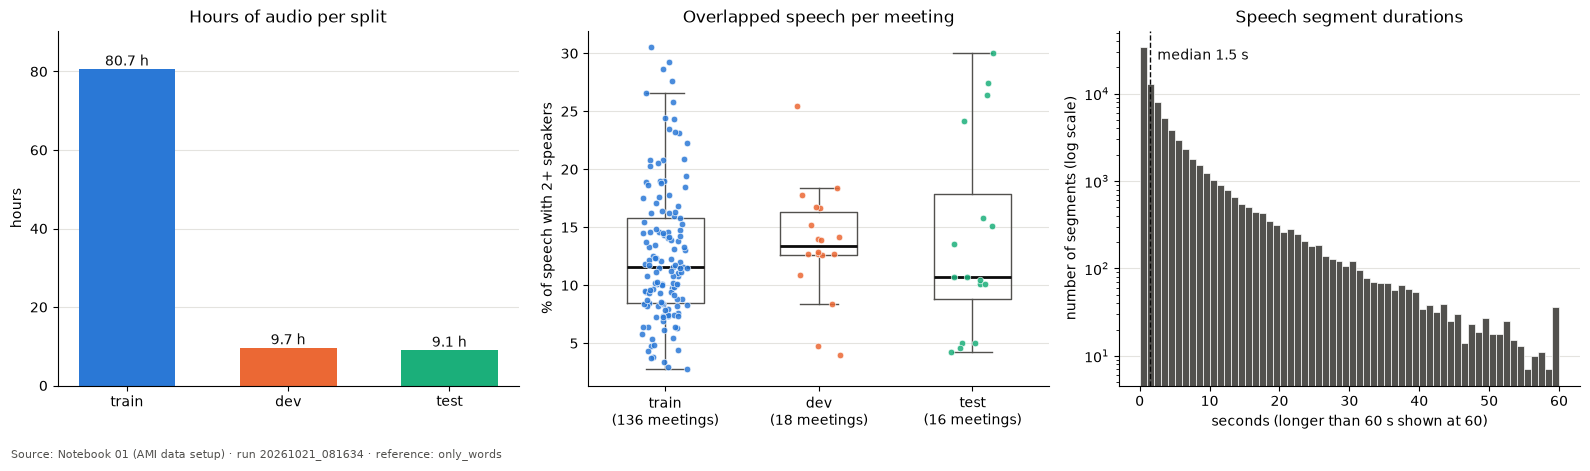

Saved: /workspace/results/figures/ami_dataset_overview_20261021_081634.png


In [17]:
# DATASET OVERVIEW FIGURE

import matplotlib.pyplot as plt



SPLIT_COLORS = {"train": "#2a78d6", "dev": "#eb6834", "test": "#1baf7a"}
NEUTRAL = "#52514e"   # for things that are not split by train/dev/test
INK     = "#0b0b0b"   # text and median lines

def tidy(ax):
    """Quiet axes: no top/right border, faint horizontal grid behind the data."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))



# Chart 1: hours of audio per split

ax = axes[0]
bars = ax.bar(SPLITS, summary["hours"], width=0.6,
              color=[SPLIT_COLORS[s] for s in SPLITS])
ax.bar_label(bars, fmt="%.1f h", color=INK)
ax.set_ylim(0, summary["hours"].max() * 1.12)   # room for the labels
ax.set_title("Hours of audio per split")
ax.set_ylabel("hours")
tidy(ax)



# Chart 2: overlapped speech - one dot per meeting, box per split

ax = axes[1]
rng = np.random.default_rng(SEED)   # same "jitter" every run

data = [per_meeting.loc[per_meeting["split"] == s, "overlap_pct_of_speech"] for s in SPLITS]

for position, (split, values) in enumerate(zip(SPLITS, data), start=1):
    x = position + rng.uniform(-0.15, 0.15, size=len(values))   # spread dots sideways
    ax.scatter(x, values, s=22, color=SPLIT_COLORS[split], alpha=0.85,
               edgecolor="white", linewidth=0.5, zorder=3)

ax.boxplot(data, positions=[1, 2, 3], widths=0.5, showfliers=False,
           medianprops={"color": INK, "linewidth": 2},
           boxprops={"color": NEUTRAL}, whiskerprops={"color": NEUTRAL},
           capprops={"color": NEUTRAL})
ax.set_xticks([1, 2, 3], [f"{s}\n({len(v)} meetings)" for s, v in zip(SPLITS, data)])
ax.set_title("Overlapped speech per meeting")
ax.set_ylabel("% of speech with 2+ speakers")
tidy(ax)



# Chart 3: how long each speech segment is 
ax = axes[2]
durations = all_segments["duration_s"].clip(upper=60)
ax.hist(durations, bins=60, color=NEUTRAL, edgecolor="white", linewidth=0.5)
ax.set_yscale("log")

median_s = all_segments["duration_s"].median()
ax.axvline(median_s, color=INK, linestyle="--", linewidth=1)
ax.text(median_s + 1, 0.95, f"median {median_s:.1f} s", color=INK,
        transform=ax.get_xaxis_transform(), va="top")

ax.set_title("Speech segment durations")
ax.set_xlabel("seconds (longer than 60 s shown at 60)")
ax.set_ylabel("number of segments (log scale)")
tidy(ax)


fig.text(0.01, -0.03,
         f"Source: Notebook 01 (AMI data setup) · run {RUN_ID} · reference: {REFERENCE_SET}",
         fontsize=8, color=NEUTRAL)

plt.tight_layout()
figure_file = FIGURES / f"ami_dataset_overview_{RUN_ID}.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_file)

**Findings**
* **Size:** train 80.7 h, dev 9.7 h, test 9.1 h (about 81 / 10 / 9 %), the standard AMI split.
* **Overlap:** most meetings have 7–15 % of speech with 2+ people talking. Pooled over each split: **train 13.4 %, dev 14.1 %, test 14.6 %**, so the test set is slightly harder than what models see in training.
* **Segments:** the largest group of speech segments is **under 1 second** (short replies such as "yeah", "okay"), with a long tail of turns longer than a minute. Short overlapping replies are exactly where speaker attribution is hardest.

## Data Samples at Each Stage 

We display sample data from each processing stage using test meeting **IS1009a**.

1. **Raw data:** Word transcripts (XML) and audio format.
2. **Transformed data:** RTTM speaker annotations and UEM evaluation regions.
3. **Preprocessing:** TS3007c segments before and after clipping.
4. **Prepared data:** Sample meetings from the train, dev, and test splits.

In [18]:
# DATA SAMPLES AT EACH STAGE


import wave
import numpy as np
import pandas as pd

SAMPLE = "IS1009a"                
sample_split = split_of[SAMPLE]   



# 1) RAW: manual word transcript (XML, from AMI)

raw_file  = sorted(words_dir.glob(f"{SAMPLE}.*.words.xml"))[0]
raw_lines = raw_file.read_text(encoding="iso-8859-1").splitlines()

print(f"1) RAW - AMI word transcript {raw_file.name} (first 10 lines)")
print("\n".join(raw_lines[:10]))



# 2) RAW: audio file format

with wave.open(str(audio_path(SAMPLE)), "rb") as w:
    print(f"\n2) RAW - audio {audio_path(SAMPLE).name}: {w.getframerate()} Hz, "
          f"{w.getnchannels()} channel(s), {8 * w.getsampwidth()}-bit, "
          f"{w.getnframes() / w.getframerate() / 60:.1f} minutes")



# 3) TRANSFORMED (by pyannote setup): reference RTTM - who spoke when

rttm_file = rttm_path(SAMPLE, sample_split)
print(f"\n3) TRANSFORMED (by pyannote setup) - reference {rttm_file.name} (first 5 lines)")
print("   format: SPEAKER <meeting> <channel> <start s> <duration s> <NA> <NA> <speaker> <NA> <NA>")
print("\n".join(rttm_file.read_text().splitlines()[:5]))
print("   the same segments as a table:")
print(read_rttm(rttm_file).head(5).round(2).to_string(index=False))



# 4) TRANSFORMED (by pyannote setup): scoring region (UEM)

uem_file = uem_path(SAMPLE, sample_split)
print(f"\n4) TRANSFORMED (by pyannote setup) - scoring region {uem_file.name}")
print("   format: <meeting> <channel> <start s> <end s>")
print(uem_file.read_text().strip())



# 5) PRE-PROCESSING (ours): before / after

with wave.open(str(audio_path("ES2010d")), "rb") as w:
    first = np.frombuffer(w.readframes(5), dtype=np.int16).reshape(-1, 2)  

stereo = pd.DataFrame(first, columns=["left", "right"])
mono   = stereo.mean(axis=1).astype(int).rename("mono")
print("\n5a) PRE-PROCESSING - ES2010d stereo -> mono (first 5 audio samples)")
print("   before:")
print(stereo.to_string(index=False))
print("   after:")
print(mono.to_frame().to_string(index=False))

# 5b) TS3007c: cut segments at the end of the audio
ts3007c   = read_rttm(rttm_path("TS3007c", "train"))
audio_end = checks.loc[checks["meeting"] == "TS3007c", "audio_s"].item()
before    = ts3007c[ts3007c["end"] > audio_end]
after     = before.assign(end=before["end"].clip(upper=audio_end))   # cut at the audio end
after     = after[after["start"] < audio_end]                         # drop segments that start after it

print(f"\n5b) PRE-PROCESSING - TS3007c, audio ends at {audio_end:.2f} s")
print("   before (segments past the end):")
print(before.round(2).to_string(index=False))
print(f"   after clipping ({len(before) - len(after)} segment(s) dropped completely):")
print(after.round(2).to_string(index=False))



# 6) PREPARED: official splits

print("\n6) PREPARED - official splits")
print(pd.DataFrame([{"split": s,
                     "meetings": len(meetings[s]),
                     "first 3 meetings": ", ".join(meetings[s][:3])}
                    for s in SPLITS]).to_string(index=False))

1) RAW - AMI word transcript IS1009a.A.words.xml (first 10 lines)
<?xml version="1.0" encoding="ISO-8859-1" standalone="yes"?>
<nite:root nite:id="IS1009a.A.words" xmlns:nite="http://nite.sourceforge.net/">
   <w nite:id="IS1009a.A.words0" starttime="54.95" endtime="55.86">Okay</w>
   <w nite:id="IS1009a.A.words1" starttime="55.86" endtime="55.86" punc="true">.</w>
   <w nite:id="IS1009a.A.words2" starttime="55.86" endtime="56.28">Everybody</w>
   <w nite:id="IS1009a.A.words3" starttime="56.28" endtime="57.69">ready</w>
   <w nite:id="IS1009a.A.words4" starttime="57.69" endtime="57.69" punc="true">?</w>
   <w nite:id="IS1009a.A.words5" starttime="57.69" endtime="58.18">Uh</w>
   <w nite:id="IS1009a.A.words6" starttime="58.18" endtime="58.25">I</w>
   <w nite:id="IS1009a.A.words7" starttime="58.25" endtime="58.44">think</w>

2) RAW - audio IS1009a.Mix-Headset.wav: 16000 Hz, 1 channel(s), 16-bit, 14.0 minutes

3) TRANSFORMED (by pyannote setup) - reference IS1009a.rttm (first 5 lines)
  

## Data Imbalance and Correlation

We analyze speaker participation and relationships between meeting characteristics.

- **Speaking-time imbalance:** Measure the percentage of speaking time contributed by the most active speaker (25% represents an equal share among four speakers).
- **Speaker distribution:** Analyze speakers by sex across splits, after verifying participant IDs using AMI documentation.
- **Correlation:** Examine relationships between meeting duration, speaker count, speech segments, overlap, and imbalance.

In [19]:
# SPEAKER BALANCE, SPEAKER SEX, AND CORRELATIONS


import pandas as pd



# 1. Talking-time balance: share of the most talkative person per meeting

talk = all_segments.groupby(["split", "meeting", "speaker"])["duration_s"].sum()

balance = (
    talk.groupby(["split", "meeting"])
        .apply(lambda t: 100 * t.max() / t.sum())    
        .rename("top_speaker_share_%")
        .reset_index()
)


# 2. Speakers per split by sex (first letter of the AMI ID: M / F)

people_table = all_segments[["split", "speaker"]].drop_duplicates()
people_table["sex_from_id"] = (people_table["speaker"].str[0]
                               .map({"M": "male", "F": "female"})
                               .fillna("unknown"))
sex_counts = (people_table.groupby(["split", "sex_from_id"]).size()
                          .unstack(fill_value=0).reindex(SPLITS))


# 3. Correlation between per-meeting properties

features = per_meeting.merge(balance, on=["split", "meeting"])[
    ["length_min", "speakers", "segments", "speech_min", "overlap_pct_of_speech", "top_speaker_share_%"]]
features.columns = ["length (min)", "speakers", "segments", "speech (min)", "overlap %", "top speaker %"]
corr = features.corr().round(2)


# 4. Show the results

print("Speakers per split by sex (from ID):")
print(sex_counts.to_string())

share = balance["top_speaker_share_%"]
print(f"\nMost talkative person's share of talking time: median {share.median():.1f}%, "
      f"max {share.max():.1f}%  (equal share for 4 people = 25%)")

print("\nCorrelation between meeting properties (-1 to 1):")
print(corr.to_string())


# 5. Check: does the AMI metadata record sex directly?

participants_xml = next(ANNOT_DIR.rglob("participants.xml"), None)
if participants_xml:
    print(f"\nFirst lines of {participants_xml.name}:")
    print("\n".join(participants_xml.read_text(encoding="iso-8859-1").splitlines()[:12]))

Speakers per split by sex (from ID):
sex_from_id  female  male
split                    
train            44   108
dev               8    13
test              8     8

Most talkative person's share of talking time: median 38.9%, max 82.9%  (equal share for 4 people = 25%)

Correlation between meeting properties (-1 to 1):
               length (min)  speakers  segments  speech (min)  overlap %  top speaker %
length (min)           1.00      0.09      0.77          0.97       0.22          -0.26
speakers               0.09      1.00      0.06          0.07      -0.14          -0.00
segments               0.77      0.06      1.00          0.74       0.62          -0.32
speech (min)           0.97      0.07      0.74          1.00       0.25          -0.26
overlap %              0.22     -0.14      0.62          0.25       1.00          -0.20
top speaker %         -0.26     -0.00     -0.32         -0.26      -0.20           1.00

First lines of participants.xml:
<?xml version="1.0" encodi

In [20]:
# SPEAKER METADATA from participants.xml


import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET

NITE_ID = "{http://nite.sourceforge.net/}id"   



# 1. Read every participant

rows = []
for p in ET.parse(participants_xml).getroot().iter("participant"):
    rows.append({
        "speaker":         p.get(NITE_ID),
        "sex":             p.get("sex"),
        "age":             p.get("age_at_collection"),
        "native_language": p.get("native_language"),
    })

participants = pd.DataFrame(rows).drop_duplicates("speaker")
participants["age"] = pd.to_numeric(participants["age"], errors="coerce")


# 2. Match to the speakers in our splits

people_meta = people_table[["split", "speaker"]].merge(participants, on="speaker", how="left")

n_found = people_meta["sex"].notna().sum()
print(f"Speakers found in participants.xml: {n_found} of {len(people_meta)}")
if n_found < len(people_meta):
    print("Not found:", people_meta.loc[people_meta["sex"].isna(), "speaker"].tolist())



# 3. Sex: metadata vs. our guess from the ID letter

known = people_meta[people_meta["sex"].notna()]
agree = (known["sex"] == known["speaker"].str[0]).mean() * 100
print(f"ID letter matches recorded sex for {agree:.0f}% of speakers")

sex_meta = (people_meta.groupby(["split", "sex"]).size()
                       .unstack(fill_value=0).reindex(SPLITS))
print("\nSpeakers per split by sex (from metadata):")
print(sex_meta.to_string())


# 4. Native language: English vs. other

def language_group(language):
  
    if pd.isna(language):
        return "unknown"
    return "English" if language == "English" else "other"

people_meta["first_language"] = people_meta["native_language"].map(language_group)
lang_counts = (people_meta.groupby(["split", "first_language"]).size()
                          .unstack(fill_value=0).reindex(SPLITS))
print("\nSpeakers per split by native language:")
print(lang_counts.to_string())

print("\nMost common native languages (all splits):")
print(people_meta["native_language"].value_counts().head(8).to_string())



# 5. Age

print("\nAge per split (median, min-max):")
for split in SPLITS:
    ages = people_meta.loc[people_meta["split"] == split, "age"].dropna()
    print(f"  {split:5s}: median {ages.median():.0f}, range {ages.min():.0f}-{ages.max():.0f}  ({len(ages)} with age)")



# 6. Save

meta_file = RESULTS / f"speaker_metadata_{RUN_ID}.csv"
people_meta.to_csv(meta_file, index=False)
print("\nSaved:", meta_file)

Speakers found in participants.xml: 149 of 189
Not found: ['MTD017PM', 'MTD018ID', 'FTD019UID', 'MTD020ME', 'MTD023UID', 'MTD024ME', 'MTD021PM', 'MTD022ID', 'MTD027ID', 'MTD026UID', 'MTD025PM', 'MTD028ME', 'MTD032ME', 'MTD029PM', 'MTD031UID', 'MTD030ID', 'MTD036ME', 'MTD035UID', 'MTD033PM', 'MTD034ID', 'MTD037PM', 'MTD040ME', 'MTD038ID', 'MTD039UID', 'MTD043UID', 'MTD041PM', 'MTD042ID', 'MTD044ME', 'MTD045PM', 'MTD047UID', 'MTD048ME', 'MTD046ID', 'MTD015UID', 'MTD013PM', 'MTD014ID', 'MTD016ME', 'MTD009PM', 'MTD011UID', 'MTD012ME', 'MTD0010ID']
ID letter matches recorded sex for 100% of speakers

Speakers per split by sex (from metadata):
sex     F   M
split        
train  43  77
dev     8   9
test    8   4

Speakers per split by native language:
first_language  English  other  unknown
split                                  
train                70     50       32
dev                   8      9        4
test                  6      6        4

Most common native languages (all splits):


In [21]:
# TS speakers: listed under another ID? If not, fall back to the ID letter

xml_ids = participants["speaker"].dropna()
print("IDs in participants.xml that contain 'TD':", xml_ids[xml_ids.str.contains("TD")].tolist()[:10])

# Fill missing sex from the ID letter (it matched 100% for the 149 we could check)
people_meta["sex_source"] = np.where(people_meta["sex"].notna(), "metadata", "id_letter")
people_meta["sex"] = people_meta["sex"].fillna(people_meta["speaker"].str[0])

print("\nSpeakers per split by sex (metadata + ID letter for TS speakers):")
print(people_meta.groupby(["split", "sex"]).size().unstack(fill_value=0).reindex(SPLITS).to_string())
print("\nWhere the sex value came from:")
print(people_meta["sex_source"].value_counts().to_string())

people_meta.to_csv(meta_file, index=False)   # save again with the filled values
print("\nSaved again:", meta_file)

IDs in participants.xml that contain 'TD': []

Speakers per split by sex (metadata + ID letter for TS speakers):
sex     F    M
split         
train  44  108
dev     8   13
test    8    8

Where the sex value came from:
sex_source
metadata     149
id_letter     40

Saved again: /workspace/results/data/speaker_metadata_20261021_081634.csv


## Imbalance, sex balance, and correlations — figure
Talking-time imbalance, % female per split, and correlations between meeting properties.

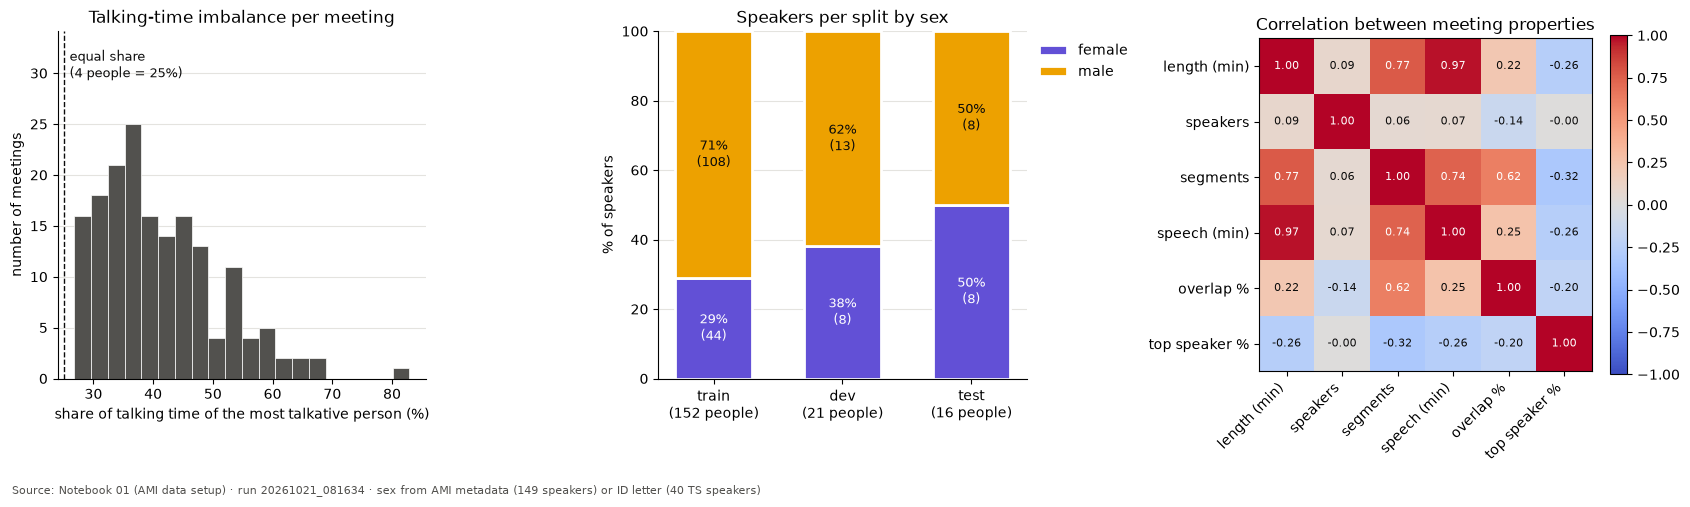

Saved: /workspace/results/figures/ami_imbalance_correlation_20261021_081634.png


In [22]:
# IMBALANCE, SEX BALANCE, AND CORRELATION FIGURE


import numpy as np
import matplotlib.pyplot as plt

NEUTRAL = "#52514e"
INK     = "#0b0b0b"
SEX_COLORS  = {"F": "#6250d6", "M": "#eda100"}   
SEX_LABELS  = {"F": "female", "M": "male"}
TEXT_ON_BAR = {"F": "white", "M": INK}            

def tidy(ax):
    
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))



# Chart 1: talking-time imbalance per meeting

ax = axes[0]
ax.hist(balance["top_speaker_share_%"], bins=20, color=NEUTRAL, edgecolor="white", linewidth=0.5)
ax.axvline(25, color=INK, linestyle="--", linewidth=1)
ax.set_ylim(0, ax.get_ylim()[1] * 1.3)          
ax.text(26, 0.95, "equal share\n(4 people = 25%)", transform=ax.get_xaxis_transform(),
        va="top", color=INK, fontsize=9)
ax.set_title("Talking-time imbalance per meeting")
ax.set_xlabel("share of talking time of the most talkative person (%)")
ax.set_ylabel("number of meetings")
tidy(ax)



# Chart 2: % female / male per split 

ax = axes[1]
sex_table = (people_meta.groupby(["split", "sex"]).size()
                        .unstack(fill_value=0).reindex(SPLITS)[["F", "M"]])
sex_pct = 100 * sex_table.div(sex_table.sum(axis=1), axis=0)

bottom = np.zeros(len(SPLITS))
for sex in ["F", "M"]:
    ax.bar(SPLITS, sex_pct[sex], bottom=bottom, width=0.6,
           color=SEX_COLORS[sex], edgecolor="white", linewidth=2, label=SEX_LABELS[sex])
    for x, (pct, count, base) in enumerate(zip(sex_pct[sex], sex_table[sex], bottom)):
        ax.text(x, base + pct / 2, f"{pct:.0f}%\n({count})", ha="center", va="center",
                color=TEXT_ON_BAR[sex], fontsize=9)
    bottom += sex_pct[sex].values

ax.set_xticks(range(len(SPLITS)), [f"{s}\n({sex_table.loc[s].sum()} people)" for s in SPLITS])
ax.set_ylim(0, 100)
ax.set_title("Speakers per split by sex")
ax.set_ylabel("% of speakers")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
tidy(ax)



# Chart 3: correlation heatmap 

ax = axes[2]
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else INK)   # white text on dark cells
ax.set_title("Correlation between meeting properties")
fig.colorbar(im, ax=ax, fraction=0.046)



fig.text(0.01, -0.04,
         f"Source: Notebook 01 (AMI data setup) · run {RUN_ID} · sex from AMI metadata "
         f"(149 speakers) or ID letter (40 TS speakers)",
         fontsize=8, color=NEUTRAL)

plt.tight_layout()
figure_file = FIGURES / f"ami_imbalance_correlation_{RUN_ID}.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()

balance.to_csv(RESULTS / f"speaker_balance_{RUN_ID}.csv", index=False)
sex_table.to_csv(RESULTS / f"speakers_by_sex_{RUN_ID}.csv")
corr.to_csv(RESULTS / f"meeting_feature_correlation_{RUN_ID}.csv")
print("Saved:", figure_file)

**Findings**
* **Talking time is unequal:** the most talkative person has a median of **38.9 %** of the talking time (max 82.9 %), while an equal share for 4 people would be 25 %. A model that is good at the main speaker can still miss the quieter people.
* **Speaker mix differs between splits:** train has 44 female / 108 male speakers (29 % female), test has 8 / 8 (50 %). We will later report results separately for female and male speakers (fairness check).
* **Correlation:** meetings with more segments have more overlap (**0.62**), meaning fast back-and-forth talk creates overlap. Number of speakers hardly correlates with anything, because almost every meeting has 4 people.

## Stage 2 · Save the cleaned data
Validation found two problems (both in **train**). Until now they were only fixed *in memory*. Here we **write the fixes to new files**, so every later step uses the same clean data. The **original downloads stay untouched** (raw data is read-only).

| Meeting | Problem | Fix | New file |
|---|---|---|---|
| ES2010d | stereo audio (two identical channels) | keep channel 1 → mono | `data_processed/audio_fixed/ES2010d.Mix-Headset.wav` |
| TS3007c | 4 reference segments run past the end of the audio | clip at the audio end | `data_processed/rttm_clean/train/TS3007c.rttm` |

All 170 reference files are written to `rttm_clean/`, so later steps have **one folder** to read from.

In [23]:
# STAGE 2: SAVE THE CLEANED DATA


import wave
import numpy as np
import pandas as pd
from pathlib import Path

for folder in [AUDIO_FIXED, RTTM_CLEAN]:
    folder.mkdir(parents=True, exist_ok=True)

cleaning_log = [] 



# Fix 1: stereo -> mono

def fixed_audio_path(meeting):

    return AUDIO_FIXED / f"{meeting}.{AUDIO_TYPE}.wav"

stereo_meetings = checks.loc[checks["channels"] == 2, "meeting"].tolist()

for meeting in stereo_meetings:
    target = fixed_audio_path(meeting)

    if not target.exists():   # only do the work once
        with wave.open(str(audio_path(meeting)), "rb") as w:
            rate, width = w.getframerate(), w.getsampwidth()
            samples = np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16).reshape(-1, 2)

        # Safe only if both channels are the same - otherwise stop
        if not np.array_equal(samples[:, 0], samples[:, 1]):
            raise ValueError(f"{meeting}: the two channels differ - keeping one would lose audio")

        # Write to a temporary file first, rename when complete
        temporary = target.with_name(target.name + ".part")
        with wave.open(str(temporary), "wb") as out:
            out.setnchannels(1)                             
            out.setsampwidth(width)                       
            out.setframerate(rate)                          
            out.writeframes(samples[:, 0].copy().tobytes())   
        temporary.replace(target)

    cleaning_log.append({"meeting": meeting,
                         "problem": "stereo audio (2 identical channels)",
                         "fix": "kept channel 1 -> mono",
                         "new_file": str(target)})



def write_rttm(segments, meeting, path):
    
    lines = [f"SPEAKER {meeting} 1 {row.start:.3f} {row.end - row.start:.3f} <NA> <NA> {row.speaker} <NA> <NA>"
             for row in segments.itertuples()]
    Path(path).write_text("\n".join(lines) + "\n")

audio_length = dict(zip(checks["meeting"], checks["audio_s"]))   

for split in SPLITS:
    (RTTM_CLEAN / split).mkdir(exist_ok=True)
    for meeting in meetings[split]:
        segments     = read_rttm(rttm_path(meeting, split))
        end_of_audio = audio_length[meeting]
        late         = segments["end"] > end_of_audio             

        if late.any():
            lost = (segments.loc[late, "end"] - segments.loc[late, "start"].clip(lower=end_of_audio)).sum()
            segments = segments.assign(end=segments["end"].clip(upper=end_of_audio))
            segments = segments[segments["end"] > segments["start"]]
            cleaning_log.append({"meeting": meeting,
                                 "problem": f"{int(late.sum())} reference segments past the audio end",
                                 "fix": f"clipped at {end_of_audio:.2f} s ({lost:.1f} s of speech removed)",
                                 "new_file": str(RTTM_CLEAN / split / f"{meeting}.rttm")})

        write_rttm(segments.sort_values("start"), meeting, RTTM_CLEAN / split / f"{meeting}.rttm")

cleaning_log = pd.DataFrame(cleaning_log)
cleaning_log.to_csv(RESULTS / f"cleaning_log_{RUN_ID}.csv", index=False)



# Which audio file to use for training

def clean_audio_path(meeting):

    fixed = fixed_audio_path(meeting)
    return fixed if fixed.exists() else audio_path(meeting)



# Check again: is every meeting usable now?

recheck = []
for split in SPLITS:
    for meeting in meetings[split]:
        with wave.open(str(clean_audio_path(meeting)), "rb") as w:
            ok_audio = (w.getframerate(), w.getnchannels(), w.getsampwidth()) == (16000, 1, 2)
            length   = w.getnframes() / w.getframerate()
        clean = read_rttm(RTTM_CLEAN / split / f"{meeting}.rttm")
        recheck.append({"split": split, "meeting": meeting, "audio_ok": ok_audio,
                        "reference_inside_audio": bool(clean["end"].max() <= length + 0.01)})

recheck = pd.DataFrame(recheck)
recheck["usable"] = recheck["audio_ok"] & recheck["reference_inside_audio"]

print(f"Usable meetings after cleaning: {int(recheck['usable'].sum())} / {len(recheck)}  "
      f"(before cleaning: {int(checks['passed'].sum())} / {len(checks)})")
cleaning_log

Usable meetings after cleaning: 170 / 170  (before cleaning: 168 / 170)


,meeting,problem,fix,new_file
0,ES2010d,stereo audio (2 identical channels),kept channel 1 -> mono,/workspace/data_processed/audio_fixed/ES2010d....
1,TS3007c,4 reference segments past the audio end,clipped at 2420.00 s (5.8 s of speech removed),/workspace/data_processed/rttm_clean/train/TS3...


## Words table
One row per word from the AMI transcripts. Speaker from meetings.xml, checked against the reference timing.

In [24]:
# STAGE 3a: WORDS TABLE (from the AMI word XML files)

import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET



# 1. Read one word file

def parse_words(xml_path):
  
    rows, n_untimed = [], 0
    for element in ET.parse(xml_path).getroot():
        if element.tag.split("}")[-1] != "w":        
            continue
        start, end = element.get("starttime"), element.get("endtime")
        if start is None or end is None:
            n_untimed += 1
            continue
        rows.append((element.text or "", float(start), float(end), element.get("punc") == "true"))
    return rows, n_untimed



# 2. Official channel -> person map from meetings.xml

agent_to_person = {}
for element in ET.parse(meetings_xml).iter():
    if local_tag(element) == "meeting":
        meeting_id = element.get("observation")
        for s in element.iter():
            if local_tag(s) == "speaker":
                agent_to_person[(meeting_id, s.get("nxt_agent"))] = s.get("global_name")

if not any(channel for (_, channel) in agent_to_person):
    raise ValueError("No 'nxt_agent' found in meetings.xml - send me one <speaker .../> line from it.")



# 3. Check by timing: which reference person speaks at these times?

def match_channel_to_speaker(word_times, segments):

    best_speaker, best_share = None, 0.0
    for speaker, group in segments.groupby("speaker"):
        starts, ends = group["start"].values, group["end"].values      # sorted by start
        position = np.searchsorted(starts, word_times, side="right") - 1
        inside = (position >= 0) & (word_times <= ends[np.clip(position, 0, None)] + 0.01)
        share = float(inside.mean()) if len(word_times) else 0.0
        if share > best_share:
            best_speaker, best_share = speaker, share
    return best_speaker, best_share



# 4. Build the table for all meetings

word_tables, channel_map = [], []
n_untimed_total, n_after_end_total = 0, 0

for split in SPLITS:
    for meeting in meetings[split]:
        segments     = read_rttm(RTTM_CLEAN / split / f"{meeting}.rttm").sort_values("start")
        end_of_audio = audio_length[meeting]

        for xml_file in sorted(words_dir.glob(f"{meeting}.*.words.xml")):
            channel = xml_file.name.split(".")[1]                   
            rows, n_untimed = parse_words(xml_file)
            n_untimed_total += n_untimed

            words = pd.DataFrame(rows, columns=["word", "start", "end", "is_punct"])
            after_end = words["start"] >= end_of_audio             
            n_after_end_total += int(after_end.sum())
            words = words[~after_end]
            if words.empty:
                continue

            person = agent_to_person.get((meeting, channel))         
            spoken = words[~words["is_punct"]]
            middle = ((spoken["start"] + spoken["end"]) / 2).values 
            time_person, share = match_channel_to_speaker(middle, segments)   

            channel_map.append({"split": split, "meeting": meeting, "channel": channel,
                                "speaker": person, "time_match": time_person,
                                "match_share": round(share, 4), "agree": person == time_person,
                                "words": len(spoken)})

            words.insert(0, "speaker", person)
            words.insert(0, "channel", channel)
            words.insert(0, "meeting", meeting)
            words.insert(0, "split", split)
            word_tables.append(words)

words_table = pd.concat(word_tables, ignore_index=True)
channel_map = pd.DataFrame(channel_map)


# 5. Report 

n_spoken = int((~words_table["is_punct"]).sum())
print(f"Words: {len(words_table):,} rows ({n_spoken:,} spoken words) "
      f"from {len(channel_map)} channel files in {channel_map['meeting'].nunique()} meetings")
print(f"Removed: {n_untimed_total:,} words without timing, "
      f"{n_after_end_total:,} words after the audio end")

n_agree = int(channel_map["agree"].sum())
print(f"\nChannel -> person: metadata and timing agree for {n_agree} of {len(channel_map)} channels")
print(f"Timing match share: lowest {channel_map['match_share'].min():.3f}, "
      f"median {channel_map['match_share'].median():.3f}")

no_person = channel_map[channel_map["speaker"].isna()]
if not no_person.empty:
    print("Channels with no person in meetings.xml:")
    print(no_person.to_string(index=False))

disagree = channel_map[~channel_map["agree"]]
if not disagree.empty:
    print("Channels where metadata and timing disagree - check these:")
    print(disagree.to_string(index=False))

duplicates = channel_map.groupby("meeting")["speaker"].apply(lambda s: s.duplicated().any())
print("Two channels mapped to the same person in:", duplicates[duplicates].index.tolist() or "no meeting")

# Run record of the channel -> person map
channel_map.to_csv(RESULTS / f"channel_map_{RUN_ID}.csv", index=False)

words_table.head(8)

Words: 1,140,219 rows (971,870 spoken words) from 678 channel files in 170 meetings
Removed: 4 words without timing, 17 words after the audio end

Channel -> person: metadata and timing agree for 678 of 678 channels
Timing match share: lowest 0.999, median 1.000
Two channels mapped to the same person in: no meeting


,split,meeting,channel,speaker,word,start,end,is_punct
0,train,IS1000a,A,FIE081,Hold,208.30,208.42,False
1,train,IS1000a,A,FIE081,that,208.42,208.68,False
2,train,IS1000a,A,FIE081,.,208.68,208.68,True
3,train,IS1000a,A,FIE081,Okay,213.26,213.44,False
4,train,IS1000a,A,FIE081,.,213.44,213.44,True
5,train,IS1000a,A,FIE081,Okay,216.64,217.54,False
6,train,IS1000a,A,FIE081,.,217.54,217.54,True
7,train,IS1000a,A,FIE081,Mm,217.54,217.97,False


In [25]:
used = set(zip(channel_map["meeting"], channel_map["channel"]))
skipped = [f.name for m in all_ids for f in sorted(words_dir.glob(f"{m}.*.words.xml"))
           if (m, f.name.split(".")[1]) not in used]
print(f"{len(skipped)} word files in our splits were skipped (no timed words):", skipped)

5 word files in our splits were skipped (no timed words): ['IN1001.D.words.xml', 'EN2003a.D.words.xml', 'EN2009b.D.words.xml', 'EN2009c.D.words.xml', 'EN2002c.D.words.xml']


## Speaker-turn table
One row per speaker turn, flagged if another person talks at the same time.

In [26]:
# STAGE 3b: SPEAKER-TURN TABLE (from the cleaned RTTMs)


import pandas as pd

turn_tables = []
for split in SPLITS:
    for meeting in meetings[split]:
      
        turns = read_rttm(RTTM_CLEAN / split / f"{meeting}.rttm").sort_values("start").reset_index(drop=True)
        starts   = turns["start"].values
        ends     = turns["end"].values
        speakers = turns["speaker"].values

  
        overlaps = [bool(((starts < ends[i]) & (ends > starts[i]) & (speakers != speakers[i])).any())
                    for i in range(len(turns))]

        turns.insert(0, "split", split)
        turns["duration_s"] = turns["end"] - turns["start"]
        turns["overlaps_other_speaker"] = overlaps
        turn_tables.append(turns)

turns_table = pd.concat(turn_tables, ignore_index=True)

print(f"Speaker turns: {len(turns_table):,}")
print(f"Turns where another person also talks: {100 * turns_table['overlaps_other_speaker'].mean():.1f}% of turns")
print("(This counts TURNS. The 13-15% from the statistics cell counts speech TIME - different measure.)")

turns_table.head(8).round(2)

Speaker turns: 82,970
Turns where another person also talks: 77.7% of turns
(This counts TURNS. The 13-15% from the statistics cell counts speech TIME - different measure.)


,split,meeting,start,end,speaker,duration_s,overlaps_other_speaker
0,train,IS1000a,37.25,38.01,MIO050,0.76,False
1,train,IS1000a,38.71,41.34,MIO016,2.63,False
2,train,IS1000a,44.93,51.42,MIO050,6.49,False
3,train,IS1000a,70.02,72.86,MIO050,2.84,False
4,train,IS1000a,93.56,97.48,MIO082,3.92,True
5,train,IS1000a,96.02,99.02,MIO050,3.00,True
6,train,IS1000a,104.96,107.68,MIO016,2.72,False
7,train,IS1000a,110.91,113.13,MIO050,2.22,False


## Summary table
Human-written abstracts, actions, decisions and problems per meeting — reference text for action-item extraction.

In [27]:
import pandas as pd
import xml.etree.ElementTree as ET


# 1. Read one summary file

def parse_summary(xml_path):
   
    rows = []
    for section in ET.parse(xml_path).getroot():
        section_name = section.tag.split("}")[-1]          
        for element in section.iter():
            if element.tag.split("}")[-1] == "sentence" and (element.text or "").strip():
                rows.append({"section": section_name, "text": element.text.strip()})
    return rows



# 2. Read all meetings in our splits

summary_dir  = ANNOT_DIR / "abstractive"
summary_rows = []
no_summary   = {split: [] for split in SPLITS}  

for split in SPLITS:
    for meeting in meetings[split]:
        summary_file = summary_dir / f"{meeting}.abssumm.xml"
        if not summary_file.exists():
            no_summary[split].append(meeting)
            continue
        for row in parse_summary(summary_file):
            summary_rows.append({"split": split, "meeting": meeting, **row})

summary_items = pd.DataFrame(summary_rows, columns=["split", "meeting", "section", "text"])



# 3. Coverage: which meetings have a summary?

print("Meetings with a summary, per split:")
for split in SPLITS:
    n_total = len(meetings[split])
    n_with  = n_total - len(no_summary[split])
    print(f"  {split:5s}: {n_with:3d} of {n_total}")
print("Test meetings WITHOUT a summary:", no_summary["test"] or "none")



# 4. Sentences per section and split

print("\nSummary sentences per section and split:")
print(summary_items.pivot_table(index="section", columns="split", values="text",
                                aggfunc="count", fill_value=0).reindex(columns=SPLITS).to_string())



# 5. Save and show examples

print("\nExample action items:")
with pd.option_context("display.max_colwidth", None):     # show full sentences
    display(summary_items[summary_items["section"] == "actions"].head(5))

Meetings with a summary, per split:
  train: 114 of 136
  dev  :  15 of 18
  test :  12 of 16
Test meetings WITHOUT a summary: ['EN2002a', 'EN2002b', 'EN2002c', 'EN2002d']

Summary sentences per section and split:
split      train  dev  test
section                    
abstract     954  141    99
actions      244   40    20
decisions    570   51    63
problems     369   42    31

Example action items:


,split,meeting,section,text
10,train,IS1000a,actions,The interface designer will work on a general design.
11,train,IS1000a,actions,The industrial designer will work on the technica function design.
12,train,IS1000a,actions,The marketing expert will think about user requirements.
30,train,IS1000b,actions,The industrial designer will try to find out which components are needed.
31,train,IS1000b,actions,The interface designer will get more specific user interface content.


In [28]:
# STAGE 3d: SAVE THE TRANSFORMED TABLES


import pandas as pd

TABLES = PROCESSED / "tables"
TABLES.mkdir(exist_ok=True)


words_table.to_parquet(TABLES / "words.parquet", index=False)
turns_table.to_parquet(TABLES / "speaker_turns.parquet", index=False)
summary_items.to_parquet(TABLES / "summary_items.parquet", index=False)
channel_map.to_csv(TABLES / "channel_to_speaker.csv", index=False)


for file in sorted(TABLES.iterdir()):
    print(f"{file.name:28s} {file.stat().st_size / 1e6:7.1f} MB")

# Check: read each file back and compare the number of rows

print()
print("words        :", len(pd.read_parquet(TABLES / "words.parquet")) == len(words_table))
print("speaker_turns:", len(pd.read_parquet(TABLES / "speaker_turns.parquet")) == len(turns_table))
print("summary_items:", len(pd.read_parquet(TABLES / "summary_items.parquet")) == len(summary_items))

channel_to_speaker.csv           0.0 MB
speaker_turns.parquet            1.3 MB
summary_items.parquet            0.1 MB
words.parquet                   12.3 MB

words        : True
speaker_turns: True
summary_items: True


## Prepared dataset
One row per meeting with file paths, statistics, and an audio fingerprint. Saved per split in `data_processed/prepared/`.

In [29]:
# STAGE 4: PREPARED DATASET - one manifest row per meeting


import json
import hashlib
import pandas as pd


# 1. Fingerprint of a file

def sha256_of(path, block_size=8 * 1024 * 1024):

    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()

def relative(path):
   
    return str(path.relative_to(WORK))


# Cache: fingerprints already calculated 
cache_file = PROCESSED / "audio_sha256_cache.json"
cache = json.loads(cache_file.read_text()) if cache_file.exists() else {}
n_new_hashes = 0



# 2. Per-meeting numbers we already have

spoken_words  = words_table[~words_table["is_punct"]].groupby("meeting").size()
action_counts = summary_items[summary_items["section"] == "actions"].groupby("meeting").size()
has_summary   = set(summary_items["meeting"])
stats         = per_meeting.set_index("meeting")


# 3. One row per meeting

rows = []
for split in SPLITS:
    for meeting in meetings[split]:
        audio = clean_audio_path(meeting)

        key = f"{audio}|{audio.stat().st_size}|{int(audio.stat().st_mtime)}"  
        if key not in cache:
            cache[key] = sha256_of(audio)
            n_new_hashes += 1

        rows.append({
            "split":         split,
            "meeting":       meeting,
            "audio_path":    relative(audio),
            "rttm_official": relative(rttm_path(meeting, split)),           
            "rttm_clean":    relative(RTTM_CLEAN / split / f"{meeting}.rttm"), 
            "uem_path":      relative(uem_path(meeting, split)),
            "minutes":       round(stats.loc[meeting, "length_min"], 2),
            "speakers":      int(stats.loc[meeting, "speakers"]),
            "segments":      int(stats.loc[meeting, "segments"]),
            "overlap_pct":   round(stats.loc[meeting, "overlap_pct_of_speech"], 2),
            "spoken_words":  int(spoken_words.get(meeting, 0)),
            "has_summary":   meeting in has_summary,                         
            "action_items":  int(action_counts.get(meeting, 0)),
            "audio_mb":      round(audio.stat().st_size / 1e6, 1),
            "audio_sha256":  cache[key],
        })

cache_file.write_text(json.dumps(cache, indent=1))
manifest = pd.DataFrame(rows)
print(f"Fingerprints: {n_new_hashes} calculated now, {len(manifest) - n_new_hashes} from cache")



# 4. Save: one file with everything + one file per split

PREPARED = PROCESSED / "prepared"
PREPARED.mkdir(exist_ok=True)

manifest.to_csv(PREPARED / "manifest_all.csv", index=False)
manifest.to_parquet(PREPARED / "manifest_all.parquet", index=False)
for split in SPLITS:
    manifest[manifest["split"] == split].to_csv(PREPARED / f"manifest_{split}.csv", index=False)


# 5. Summary and sample rows

print()
print(manifest.groupby("split").agg(
        meetings     = ("meeting", "count"),
        hours        = ("minutes", lambda m: round(m.sum() / 60, 1)),
        spoken_words = ("spoken_words", "sum"),
        with_summary = ("has_summary", "sum"),
        action_items = ("action_items", "sum"),
        audio_gb     = ("audio_mb", lambda m: round(m.sum() / 1000, 2)),
      ).reindex(SPLITS).to_string())

print("\nSample rows (2 per split):")
manifest.groupby("split", sort=False).head(2).drop(columns=["audio_path", "rttm_official", "rttm_clean", "uem_path"])

Fingerprints: 0 calculated now, 170 from cache

       meetings  hours  spoken_words  with_summary  action_items  audio_gb
split                                                                     
train       136   80.7        788612           114           244      9.29
dev          18    9.7         94430            15            40      1.11
test         16    9.1         88828            12            20      1.04

Sample rows (2 per split):


,split,meeting,minutes,speakers,segments,overlap_pct,spoken_words,has_summary,action_items,audio_mb,audio_sha256
0,train,IS1000a,26.38,4,389,10.80,2893,True,3,50.6,25c9a48237c1f23bc419702f89234467a1b9efedbac16d...
1,train,IS1000b,39.06,4,507,10.08,5778,True,3,75.0,0f71e5018a283adf85e949f456a4c360d4fb8d9c195d29...
136,dev,IS1008a,15.73,4,169,4.03,2504,True,4,30.2,75ae8796ca2177fa0c77055de2fe2f95325b412dc7152a...
137,dev,IS1008b,29.48,4,323,4.76,4314,True,4,56.6,0d992a210480c6e9652b317ed7f66261e80a1aa86f7e5c...
154,test,IS1009a,13.98,4,195,13.57,1986,True,3,26.8,6eb5a0ede0d9e72794f976ce7bea5b78133eae969f99b4...
155,test,IS1009b,34.21,4,389,10.09,6091,True,1,65.7,07c2891ae6ad7c507b2a4f15b2dcd0a2343491df9e4e6a...


## Warehouse (local prototype)
Loads all tables into a DuckDB file, checks row counts, and shows schemas. Cloud pipeline comes later.

In [30]:
# WAREHOUSE (local prototype): load every table into DuckDB


import duckdb
import pandas as pd

WAREHOUSE = WORK / "warehouse"
WAREHOUSE.mkdir(exist_ok=True)
warehouse_file = WAREHOUSE / "ami.duckdb"



# 1. Load the tables

warehouse_tables = {
    "meetings":           manifest,
    "speaker_turns":      turns_table,
    "words":              words_table,
    "summary_items":      summary_items,
    "data_checks":        checks,
    "cleaning_log":       cleaning_log,
    "channel_to_speaker": channel_map,
}

con = duckdb.connect(str(warehouse_file))  

for name, table in warehouse_tables.items():
    con.register("incoming", table)         
    con.execute(f"CREATE OR REPLACE TABLE {name} AS SELECT * FROM incoming")
    con.unregister("incoming")



# 2. Check: rows in the warehouse = rows in memory

check_rows = []
for name, table in warehouse_tables.items():
    in_warehouse = con.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
    n_columns    = len(con.execute(f"DESCRIBE {name}").fetchall())
    check_rows.append({"table": name, "rows": in_warehouse, "columns": n_columns,
                       "matches_memory": in_warehouse == len(table)})
row_counts = pd.DataFrame(check_rows)

print("Warehouse file:", warehouse_file)
print(row_counts.to_string(index=False))
assert row_counts["matches_memory"].all(), "Some tables were not loaded completely!"



# 3. Schemas: column names and types of each table

print("\nSchemas:")
for name in warehouse_tables:
    columns = con.execute(f"DESCRIBE {name}").fetchall()     # (name, type, ...)
    print(f"  {name}: " + ", ".join(f"{c[0]} ({c[1]})" for c in columns))



# 4. Example query: overlap and speech per split

print("\nExample SQL query - turns and overlap per split:")
example = con.execute("""
    SELECT split,
           COUNT(*)                                   AS turns,
           ROUND(100 * AVG(overlaps_other_speaker::INT), 1) AS pct_turns_overlapping,
           ROUND(SUM(duration_s) / 3600, 1)           AS speech_hours
    FROM speaker_turns
    GROUP BY split
    ORDER BY CASE split WHEN 'train' THEN 1 WHEN 'dev' THEN 2 ELSE 3 END
""").df()
print(example.to_string(index=False))



# 5. Close the connection 
con.close()

Warehouse file: /workspace/warehouse/ami.duckdb
             table    rows  columns  matches_memory
          meetings     170       15            True
     speaker_turns   82970        7            True
             words 1140219        8            True
     summary_items    2624        4            True
       data_checks     170       16            True
      cleaning_log       2        4            True
channel_to_speaker     678        8            True

Schemas:
  meetings: split (VARCHAR), meeting (VARCHAR), audio_path (VARCHAR), rttm_official (VARCHAR), rttm_clean (VARCHAR), uem_path (VARCHAR), minutes (DOUBLE), speakers (BIGINT), segments (BIGINT), overlap_pct (DOUBLE), spoken_words (BIGINT), has_summary (BOOLEAN), action_items (BIGINT), audio_mb (DOUBLE), audio_sha256 (VARCHAR)
  speaker_turns: split (VARCHAR), meeting (VARCHAR), start (DOUBLE), end (DOUBLE), speaker (VARCHAR), duration_s (DOUBLE), overlaps_other_speaker (BOOLEAN)
  words: split (VARCHAR), meeting (VARCHAR),

In [31]:
# WAREHOUSE: example questions answered with SQL


import duckdb

SPLIT_ORDER = "CASE split WHEN 'train' THEN 1 WHEN 'dev' THEN 2 ELSE 3 END"   # train -> dev -> test

with duckdb.connect(str(warehouse_file), read_only=True) as con:

    print("1) Hours and meetings per split")
    print(con.sql(f'''
        SELECT split, COUNT(*) AS meetings, ROUND(SUM(minutes) / 60, 1) AS hours
        FROM meetings
        GROUP BY split
        ORDER BY {SPLIT_ORDER}
    ''').df().to_string(index=False))

    print("\n2) The 5 meetings with the most overlapped speech (hardest for diarization)")
    print(con.sql('''
        SELECT split, meeting, overlap_pct, speakers, minutes
        FROM meetings
        ORDER BY overlap_pct DESC
        LIMIT 5
    ''').df().to_string(index=False))

    print("\n3) Summaries, action items and decisions per split (JOIN of two tables)")
    print(con.sql(f'''
        SELECT m.split,
               COUNT(DISTINCT m.meeting)                                        AS meetings,
               COUNT(DISTINCT s.meeting)                                        AS with_summary,
               CAST(SUM(CASE WHEN s.section = 'actions'   THEN 1 ELSE 0 END) AS INTEGER) AS action_items,
               CAST(SUM(CASE WHEN s.section = 'decisions' THEN 1 ELSE 0 END) AS INTEGER) AS decisions
        FROM meetings m
        LEFT JOIN summary_items s ON m.meeting = s.meeting
        GROUP BY m.split
        ORDER BY {SPLIT_ORDER.replace("split", "m.split")}
    ''').df().to_string(index=False))

1) Hours and meetings per split
split  meetings  hours
train       136   80.7
  dev        18    9.7
 test        16    9.1

2) The 5 meetings with the most overlapped speech (hardest for diarization)
split meeting  overlap_pct  speakers  minutes
train IS1006d        30.54         4    30.65
 test EN2002d        30.02         4    36.83
train  IN1012        29.21         4    51.82
train IS1003d        28.63         4    35.01
train  IN1013        27.63         4    52.37

3) Summaries, action items and decisions per split (JOIN of two tables)
split  meetings  with_summary  action_items  decisions
train       136           114           244        570
  dev        18            15            40         51
 test        16            12            20         63


## Data-quality checks
Automatic checks on splits, audio, tables, warehouse, and locked settings. Stops the notebook if any check fails.

In [32]:
import duckdb
import pandas as pd

total_meetings = sum(len(m) for m in meetings.values())
quality = []

def check(name, passed, detail):
  
    quality.append({"check": name, "passed": bool(passed), "detail": detail})



# 1. Splits

check("every meeting is in the manifest",
      len(manifest) == total_meetings, f"{len(manifest)} / {total_meetings}")
check("no meeting in two splits",
      manifest["meeting"].is_unique, "unique meeting IDs")

shared_train_dev  = len(people["train"] & people["dev"])
shared_train_test = len(people["train"] & people["test"])
shared_dev_test   = len(people["dev"]   & people["test"])
check("no person in two splits",
      shared_train_dev + shared_train_test + shared_dev_test == 0,
      f"shared people: train-dev {shared_train_dev}, train-test {shared_train_test}, dev-test {shared_dev_test}")



# 2. Audio and references (after cleaning)

check("all audio is 16 kHz mono 16-bit",
      recheck["audio_ok"].all(), f"{int(recheck['audio_ok'].sum())} / {len(recheck)}")
check("all reference speech lies inside the audio",
      recheck["reference_inside_audio"].all(),
      f"{int(recheck['reference_inside_audio'].sum())} / {len(recheck)}")
check("every audio file has a SHA-256 fingerprint",
      manifest["audio_sha256"].str.len().eq(64).all(), "64-character SHA-256 recorded")



# 3. Transformed tables

turns_expected = sum(len(read_rttm(RTTM_CLEAN / s / f"{m}.rttm")) for s in SPLITS for m in meetings[s])
check("speaker_turns rows = segments in clean RTTMs",
      len(turns_table) == turns_expected, f"{len(turns_table):,} vs {turns_expected:,}")
check("every meeting has word transcripts",
      (manifest["spoken_words"] > 0).all(),
      f"{int((manifest['spoken_words'] > 0).sum())} / {len(manifest)}")
check("channel -> person: metadata and timing agree",
      channel_map["agree"].all(), f"{int(channel_map['agree'].sum())} / {len(channel_map)} channels")
check("action-item labels found",
      (summary_items["section"] == "actions").sum() > 0,
      f"{int((summary_items['section'] == 'actions').sum())} action sentences")



# 4. Warehouse: same rows as in memory

with duckdb.connect(str(warehouse_file), read_only=True) as con:
    mismatched = [name for name, table in warehouse_tables.items()
                  if con.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0] != len(table)]
check("warehouse tables match memory",
      not mismatched, f"mismatched: {mismatched}" if mismatched else f"all {len(warehouse_tables)} tables match")



# 5. Locked scoring settings have not been changed

locked = {"EVAL_SPLIT": (EVAL_SPLIT, "test"), "REFERENCE_SET": (REFERENCE_SET, "only_words"),
          "AUDIO_TYPE": (AUDIO_TYPE, "Mix-Headset"), "COLLAR": (COLLAR, 0.0),
          "SKIP_OVERLAP": (SKIP_OVERLAP, False)}
changed = [name for name, (now, locked_value) in locked.items() if now != locked_value]
check("locked scoring settings unchanged",
      not changed, f"changed: {changed}" if changed else "test / only_words / Mix-Headset / collar 0 / overlap scored")



# 6. Report - and stop if anything failed

quality = pd.DataFrame(quality)
quality_file = RESULTS / f"quality_report_{RUN_ID}.csv"
quality.to_csv(quality_file, index=False)

n_passed = int(quality["passed"].sum())
print(f"Quality checks passed: {n_passed} / {len(quality)}")
print("Saved:", quality_file)
display(quality)

if n_passed < len(quality):
    failed = quality.loc[~quality["passed"], "check"].tolist()
    raise RuntimeError(f"Data-quality checks FAILED: {failed} - fix before training or evaluation.")

Quality checks passed: 12 / 12
Saved: /workspace/results/data/quality_report_20261021_081634.csv


,check,passed,detail
0,every meeting is in the manifest,True,170 / 170
1,no meeting in two splits,True,unique meeting IDs
2,no person in two splits,True,"shared people: train-dev 0, train-test 0, dev-..."
3,all audio is 16 kHz mono 16-bit,True,170 / 170
4,all reference speech lies inside the audio,True,170 / 170
5,every audio file has a SHA-256 fingerprint,True,64-character SHA-256 recorded
6,speaker_turns rows = segments in clean RTTMs,True,"82,970 vs 82,970"
7,every meeting has word transcripts,True,170 / 170
8,channel -> person: metadata and timing agree,True,678 / 678 channels
9,action-item labels found,True,304 action sentences


In [33]:
# DEMO ONLY: pretend one audio file is broken
#recheck.loc[0, "audio_ok"] = False

## Run log
Records this run in the warehouse (`pipeline_runs`) and shows the history of all runs.

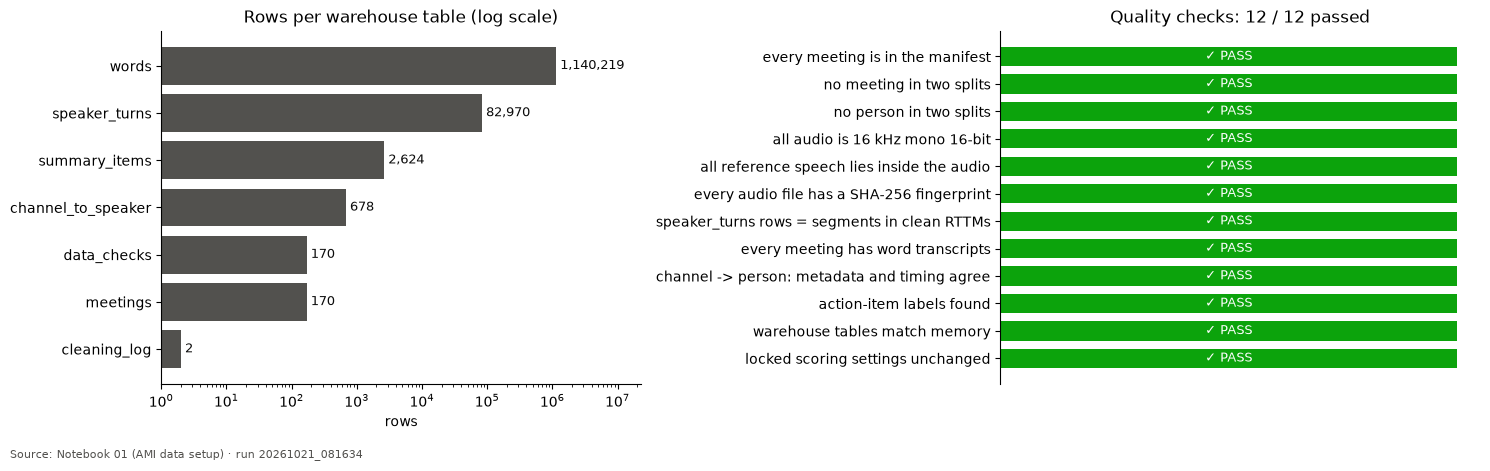

Saved: /workspace/results/figures/pipeline_monitoring_20261021_081634.png

Run history (one row per run of this notebook):


,run_id,finished_utc,checks_passed,checks_total,meetings,audio_gb,speaker_turns,words,summary_items,cleaning_fixes
0,20261021_042125,2026-10-21 04:23:30,10,10,170,11.45,82970,1140236,2624,2
1,20261021_043322,2026-10-21 04:34:27,10,10,170,11.45,82970,1140236,2624,2
2,20261021_081634,2026-10-21 08:20:37,12,12,170,11.45,82970,1140219,2624,2


In [34]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone



# 1. One row describing this run

run = pd.DataFrame([{
    "run_id":         RUN_ID,
    "finished_utc":   datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
    "checks_passed":  int(quality["passed"].sum()),
    "checks_total":   len(quality),
    "meetings":       len(manifest),
    "audio_gb":       round(manifest["audio_mb"].sum() / 1000, 2),
    "speaker_turns":  len(turns_table),
    "words":          len(words_table),
    "summary_items":  len(summary_items),
    "cleaning_fixes": len(cleaning_log),
}])



# 2. Add it to the pipeline_runs table 

with duckdb.connect(str(warehouse_file)) as con:
    con.register("incoming", run)
    con.execute("CREATE TABLE IF NOT EXISTS pipeline_runs AS SELECT * FROM incoming WHERE 1 = 0") 
    con.execute("DELETE FROM pipeline_runs WHERE run_id = ?", [RUN_ID])                          
    con.execute("INSERT INTO pipeline_runs SELECT * FROM incoming")
    con.unregister("incoming")
    history = con.sql("SELECT * FROM pipeline_runs ORDER BY finished_utc").df()



# 3. Figure: rows per table (left) and quality checks (right)

NEUTRAL, INK = "#52514e", "#0b0b0b"
PASS_COLOR, FAIL_COLOR = "#0ca30c", "#d03b3b"

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Left: rows per warehouse table
ax = axes[0]
counts = row_counts.sort_values("rows")
bars = ax.barh(counts["table"], counts["rows"], color=NEUTRAL)
ax.bar_label(bars, labels=[f"{n:,}" for n in counts["rows"]], padding=3, color=INK, fontsize=9)
ax.set_xscale("log")
ax.set_xlim(1, counts["rows"].max() * 20)          # room for the labels
ax.set_title("Rows per warehouse table (log scale)")
ax.set_xlabel("rows")
ax.spines[["top", "right"]].set_visible(False)

# Right: quality checks - colour AND text, so it also reads without colour
ax = axes[1]
colors = [PASS_COLOR if ok else FAIL_COLOR for ok in quality["passed"]]
ax.barh(quality["check"], [1] * len(quality), color=colors, height=0.7)
for i, ok in enumerate(quality["passed"]):
    ax.text(0.5, i, "✓ PASS" if ok else "✗ FAIL", ha="center", va="center", color="white", fontsize=9)
ax.invert_yaxis()                                   # first check at the top
ax.set_xticks([])
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.set_title(f"Quality checks: {int(quality['passed'].sum())} / {len(quality)} passed")

fig.text(0.01, -0.03, f"Source: Notebook 01 (AMI data setup) · run {RUN_ID}", fontsize=8, color=NEUTRAL)
plt.tight_layout()
figure_file = FIGURES / f"pipeline_monitoring_{RUN_ID}.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_file)


# 4. Run history

print("\nRun history (one row per run of this notebook):")
history

## Stage summary
One table from raw data to the prepared dataset 

In [35]:
import pandas as pd

n_word_files_used = len(channel_map)   
n_word_files_all  = n_word_files_used + len(skipped) if "skipped" in globals() else None

word_files_text = (f"{n_word_files_all} word files ({n_word_files_used} with timed words, "
                   f"{len(skipped)} empty)" if n_word_files_all else f"{n_word_files_used} word files with timed words")

stage_summary = pd.DataFrame([
    {"stage": "1 · Raw",
     "what":  "downloaded audio, reference RTTMs, word XML files",
     "result": f"{len(checks)} audio files, {int(checks['rttm_exists'].sum())} RTTMs, {word_files_text}"},
    {"stage": "2 · Pre-processed",
     "what":  "validation checks + saved fixes",
     "result": f"{int(checks['passed'].sum())}/{len(checks)} passed at first -> "
               f"{int(recheck['usable'].sum())}/{len(recheck)} usable after {len(cleaning_log)} fixes"},
    {"stage": "3 · Transformed",
     "what":  "words, speaker turns, summary sentences (Parquet)",
     "result": f"{len(words_table):,} words | {len(turns_table):,} turns | {len(summary_items):,} summary sentences"},
    {"stage": "4 · Prepared",
     "what":  "manifest per split (+ SHA-256 fingerprints)",
     "result": ", ".join(f"{s} {int((manifest['split'] == s).sum())}" for s in SPLITS) + " meetings"},
    {"stage": "Warehouse",
     "what":  "DuckDB tables + run history",
     "result": f"{len(row_counts) + 1} tables, {len(history)} run(s) recorded"},
])

summary_file = RESULTS / f"stage_summary_{RUN_ID}.csv"
stage_summary.to_csv(summary_file, index=False)
print("Saved:", summary_file)

with pd.option_context("display.max_colwidth", None):  
    display(stage_summary)

Saved: /workspace/results/data/stage_summary_20261021_081634.csv


,stage,what,result
0,1 · Raw,"downloaded audio, reference RTTMs, word XML files","170 audio files, 170 RTTMs, 683 word files (678 with timed words, 5 empty)"
1,2 · Pre-processed,validation checks + saved fixes,168/170 passed at first -> 170/170 usable after 2 fixes
2,3 · Transformed,"words, speaker turns, summary sentences (Parquet)","1,140,219 words | 82,970 turns | 2,624 summary sentences"
3,4 · Prepared,manifest per split (+ SHA-256 fingerprints),"train 136, dev 18, test 16 meetings"
4,Warehouse,DuckDB tables + run history,"8 tables, 3 run(s) recorded"


## Install conda
Installs Miniforge into `/workspace` (once). Needed to create the separate pyannote 2.1 environment.

In [39]:

import logging
import platform
import subprocess
from pathlib import Path

CONDA     = WORK / "miniforge3"
CONDA_BIN = CONDA / "bin" / "conda"
INSTALLER = Path("/tmp/miniforge.sh")
URL = ("https://github.com/conda-forge/miniforge/releases/latest/download/"
       f"Miniforge3-Linux-{platform.machine()}.sh")          # x86_64 on RunPod


# 1. Install only if the conda program is missing
if CONDA_BIN.exists():
    print("Conda already installed - skipping.")
else:
    print("Installing Miniforge ...")
    subprocess.run(["wget", "-q", URL, "-O", str(INSTALLER)], check=True)
    # -b = no questions, -u = install into an existing folder WITHOUT deleting it
    subprocess.run(["bash", str(INSTALLER), "-b", "-u", "-p", str(CONDA)], check=True)
    INSTALLER.unlink(missing_ok=True)


# 2. Check that conda really works, and record its version
result = subprocess.run([str(CONDA_BIN), "--version"], capture_output=True, text=True, check=True)
conda_version = result.stdout.strip()

print("Working:", conda_version, "at", CONDA)
logging.info(f"conda: {conda_version}")
_ = (LOG_DIR / f"conda_version_{RUN_ID}.txt").write_text(conda_version + "\n")

Conda already installed - skipping.
Working: conda 26.7.2 at /workspace/miniforge3


## Create the pyannote 2.1 environment
Separate Python 3.9 environment with PyTorch 1.13.1 and pyannote.audio 2.1.1, tested on the GPU.

In [40]:
import shutil
import subprocess

ENV_PYTHON = ENV / "bin" / "python"
ENV_PIP    = [str(ENV_PYTHON), "-m", "pip", "install", "-q"]


TORCH_PACKAGES = ["torch==1.13.1", "torchaudio==0.13.1"]
TORCH_INDEX    = "https://download.pytorch.org/whl/cu117"
OTHER_PACKAGES = ["pyannote.audio==2.1.1", "numpy<1.24", "huggingface_hub<0.20", "setuptools<70",
                  "typer[all]==0.9.0", "pandas==1.5.3", "matplotlib==3.7.5", "ipykernel==6.29.5"]


# 1. Create the environment (only once)
if ENV_PYTHON.exists():
    print("Environment already exists - skipping create and install.")
else:
    if ENV.exists():
        print(f"Found a broken environment (no Python inside) - removing {ENV}")
        shutil.rmtree(ENV)

    print("Creating environment (Python 3.9) ...")
    subprocess.run([str(CONDA_BIN), "create", "-y", "-q", "-p", str(ENV), "python=3.9"], check=True)

    print("Installing PyTorch 1.13.1 (CUDA 11.7) ...")
    subprocess.run(ENV_PIP + TORCH_PACKAGES + ["--index-url", TORCH_INDEX], check=True)

    print("Installing pyannote.audio 2.1.1 and helpers ...")
    subprocess.run(ENV_PIP + OTHER_PACKAGES, check=True)


# 2. Test: are installed packages in conflict?
check = subprocess.run([str(ENV_PYTHON), "-m", "pip", "check"], capture_output=True, text=True)
print("pip check:", check.stdout.strip() or "no problems")


# 3. Test: can we import pyannote and use the GPU?
test_code = '''
import sys, torch, pyannote.audio
print("python", sys.version.split()[0], "| torch", torch.__version__, "| pyannote", pyannote.audio.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.randn(256, 256)
    gpu_result = (x.cuda() @ x.cuda()).cpu()
    cpu_result = x @ x
    ok = torch.isfinite(gpu_result).all() and torch.allclose(gpu_result, cpu_result, atol=1e-3)
    print("GPU math test:", "passed" if ok else "FAILED")
'''
test = subprocess.run([str(ENV_PYTHON), "-c", test_code], capture_output=True, text=True)
print(test.stdout)
if test.returncode != 0 or "FAILED" in test.stdout:
    print(test.stderr[-1500:])
    raise RuntimeError("Environment test failed - see the message above.")


# 4. Save the exact package list (commit this file to the repo!)
freeze = subprocess.run([str(ENV_PYTHON), "-m", "pip", "freeze"],
                        capture_output=True, text=True, check=True).stdout
env_file = LOG_DIR / f"requirements_pyannote21_{RUN_ID}.txt"
env_file.write_text(freeze)
logging.info(f"pyannote21 env: {test.stdout.splitlines()[0]}")
print(f"Exact versions ({len(freeze.splitlines())} packages) saved to {env_file}")

Environment already exists - skipping create and install.
pip check: No broken requirements found.
python 3.9.23 | torch 1.13.1+cu117 | pyannote 2.1.1
GPU available: True
GPU: NVIDIA A40
GPU math test: passed

Exact versions (128 packages) saved to /workspace/logs/requirements_pyannote21_20261021_081634.txt


## Register the pyannote kernel
Adds "Python (pyannote 2.1)" to Jupyter, so Notebook 02 can run inside this environment.
Re-run after a pod restart (the kernel list is not stored in /workspace).

In [41]:
import json
import subprocess

subprocess.run([str(ENV_PYTHON), "-m", "ipykernel", "install", "--user",
                "--name", "pyannote21", "--display-name", "Python (pyannote 2.1)"],
               check=True, capture_output=True)

# Check: is the new kernel in Jupyter's list?
kernels = json.loads(subprocess.run(["jupyter", "kernelspec", "list", "--json"],
                                    capture_output=True, text=True, check=True).stdout)["kernelspecs"]
if "pyannote21" in kernels:
    print("Kernel registered: Python (pyannote 2.1)")
    print("Next: open Notebook 02 and choose this kernel (top-right).")
else:
    raise RuntimeError("Kernel 'pyannote21' not found after install.")

Kernel registered: Python (pyannote 2.1)
Next: open Notebook 02 and choose this kernel (top-right).
